# 🎯 Proyecto del módulo — Transformer con puntero para el WTAP

**Modelo encoder–decoder con atención que aprende a resolver el *Weapon-Target Assignment Problem* imitando a un algoritmo experto.**

Este notebook acompaña la presentación final del módulo y sigue sus cinco secciones. Parte de lo construido en las Tareas 4 (MLP) y 5 (atención + puntero) y agrega lo que pide la guía de la presentación: arquitectura descrita como **encoder + decoder**, **tabla completa de hiperparámetros**, análisis de **convergencia**, comparación con baselines (incluido un **constructivo aleatorio**) con **media ± desviación estándar**, y **desempeño por tamaño de instancia**.

> **Decisión que toma el modelo en cada paso:** dado el estado actual (qué armas ya se asignaron y a qué objetivos), **¿qué arma asigno ahora y a qué objetivo?** Cada acción posible es un par (arma $i$ → objetivo $j$) y se representa como **una fila** de la secuencia de entrada.

| Sección del notebook | Contenido | Sección de la presentación |
|---|---|---|
| 2–3 | Problema, entorno, heurística MMR y experto ILS | 1. Introducción al problema |
| 4 | Descomposición de soluciones en (estado, acciones, acción escogida) | 3. Generación de datos |
| 5 | Representación del estado (`state2vec`) y justificación de cada feature | 2. Representación y features |
| 6 | Codificación de la salida y construcción del dataset | 3. Generación de datos |
| 7 | Arquitectura: encoder + decoder (`WTAP_Attention`) | 4. Arquitectura |
| 8 | Configuración experimental, entrenamiento y convergencia | 5.1 y 5.2 |
| 9 | Evaluación post-entrenamiento (media ± desviación, baselines) | 5.3 |
| 10 | Desempeño por tamaño de instancia | 5.4 |
| 11 | Discusión y conclusiones | 5.5 |

> ⏱️ El notebook completo tarda unos 30 minutos en una CPU de 4 núcleos (casi todo es entrenamiento). Si en Colab hay GPU (*Entorno de ejecución → Cambiar tipo de entorno*), se usa automáticamente.

## 1. Instalación y librerías

Usamos la librería del curso [`eda`](https://github.com/rilianx/eda) para el `GreedyAgent` y el `SingleAgentSolver` (los mismos del TSP y de la Tarea 4). El entorno del WTAP lo implementamos nosotros en la sección 2 con la misma interfaz que `TSP_Environment`.

In [1]:
!test -d eda || git clone -q https://github.com/rilianx/eda.git

In [2]:
import os, json, time, copy, random, itertools
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from copy import deepcopy
from torch.utils.data import TensorDataset, DataLoader

from eda.agents import SingleAgentSolver, GreedyAgent
from eda.utils import handle_multiple_states

N_WEAPONS = 10   # W de las instancias de ENTRENAMIENTO (luego probaremos con instancias más grandes)
N_TARGETS = 8    # T de las instancias de entrenamiento
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

os.makedirs("figuras_proyecto", exist_ok=True)
def guardar(fig, nombre):
    fig.savefig(f"figuras_proyecto/{nombre}.png", dpi=160, bbox_inches="tight")

Dispositivo: cpu


## 2. El problema y el entorno

Tenemos **W armas** y **T objetivos**. El objetivo $j$ tiene un **valor** $V_j$ y el arma $i$ lo destruye con **probabilidad** $p_{ij}$ (disparos independientes; $q_{ij} = 1 - p_{ij}$ es la probabilidad de que sobreviva). Cada arma se asigna como máximo a un objetivo y un objetivo puede recibir varias armas. Se minimiza el **valor esperado que sobrevive**:

$$\min_x \; Z = \sum_{j=1}^{T} V_j \prod_{i=1}^{W} (1 - p_{ij})^{x_{ij}}$$

Llamamos $q_j = \prod_i (1-p_{ij})^{x_{ij}}$ a la **probabilidad de que el objetivo $j$ sobreviva** con las armas asignadas hasta ahora. Como en la Tarea 4, las instancias siguen la literatura (Ahuja et al., 2007): $V_j \sim U\{25,\dots,100\}$ y $p_{ij} \sim U(0{,}6;\ 0{,}9)$. Entrenamos con **W = 10, T = 8**, pero el modelo aceptará cualquier tamaño.

### Acciones constructivas por pares
- **Estado inicial:** ninguna arma asignada (`assignment = [-1, …, -1]`).
- **Acción** `("constructive", (i, j))`: asignar el **arma libre** $i$ al objetivo $j$. Con $k$ armas libres hay $k \cdot T$ acciones posibles (80 al inicio).
- Para el experto mantenemos los movimientos de **búsqueda local** de la Tarea 4 sobre soluciones completas: `("reassign", (i, j))` y `("swap", (i, k))`.

In [3]:
class WTAP_Instance:
    def __init__(self, values, probs):
        self.values = np.asarray(values, dtype=float)   # V_j,  forma (T,)
        self.probs  = np.asarray(probs,  dtype=float)   # p_ij, forma (W, T)
        self.n_weapons, self.n_targets = self.probs.shape

    @staticmethod
    def random(n_weapons=N_WEAPONS, n_targets=N_TARGETS, rng=np.random):
        values = rng.randint(25, 101, size=n_targets).astype(float)
        probs  = rng.uniform(0.6, 0.9, size=(n_weapons, n_targets))
        return WTAP_Instance(values, probs)


class WTAP_State:
    # assignment[i] = objetivo asignado al arma i (-1 si el arma i aún está libre)
    def __init__(self, inst_info, assignment=None):
        self.inst_info = inst_info
        self.assignment = list(assignment) if assignment is not None else [-1] * inst_info.n_weapons
        self.update_cost()

    def update_cost(self):
        # q_j = prob. de que el objetivo j sobreviva; costo = valor esperado que sobrevive
        P = self.inst_info.probs
        self.q = np.ones(self.inst_info.n_targets)
        for i, j in enumerate(self.assignment):
            if j >= 0:
                self.q[j] *= 1 - P[i, j]
        self.cost = float(self.inst_info.values @ self.q)
        return self.cost

    @property
    def free_weapons(self):
        return [i for i, j in enumerate(self.assignment) if j < 0]

    @property
    def is_complete(self):
        return all(j >= 0 for j in self.assignment)

    def __deepcopy__(self, memo):
        return type(self)(self.inst_info, list(self.assignment))

    def __str__(self):
        return (f"Asignación (arma -> objetivo): {self.assignment}\n"
                f"Valor esperado que sobrevive: {self.cost:.3f}")


class WTAP_Environment:
    @staticmethod
    def gen_actions(state, type, shuffle=False):
        inst = state.inst_info
        if type == "constructive":     # todos los pares (arma libre, objetivo)
            actions = [("constructive", (i, j)) for i in state.free_weapons for j in range(inst.n_targets)]
        elif type == "reassign":
            actions = [("reassign", (i, j)) for i in range(inst.n_weapons)
                       for j in range(inst.n_targets) if j != state.assignment[i]]
        elif type == "swap":
            a = state.assignment
            actions = [("swap", (i, k)) for i in range(inst.n_weapons)
                       for k in range(i + 1, inst.n_weapons) if a[i] != a[k]]
        else:
            raise NotImplementedError(f"Tipo de acción '{type}' no implementado")
        if shuffle:
            random.shuffle(actions)
        for action in actions:
            yield action

    @staticmethod
    def state_transition(state, action):
        P, V = state.inst_info.probs, state.inst_info.values
        kind, arg = action
        if kind == "constructive" and state.assignment[arg[0]] < 0:   # asignar el arma libre i al objetivo j
            i, j = arg
            state.assignment[i] = j
            state.q[j] *= 1 - P[i, j]
        elif kind == "reassign" and state.is_complete:                 # mover el arma i al objetivo j
            i, j = arg
            a = state.assignment[i]
            state.q[a] /= 1 - P[i, a]
            state.q[j] *= 1 - P[i, j]
            state.assignment[i] = j
        elif kind == "swap" and state.is_complete:                     # intercambiar objetivos de i y k
            i, k = arg
            a, b = state.assignment[i], state.assignment[k]
            state.q[a] *= (1 - P[k, a]) / (1 - P[i, a])
            state.q[b] *= (1 - P[i, b]) / (1 - P[k, b])
            state.assignment[i], state.assignment[k] = b, a
        else:
            raise NotImplementedError(f"Movimiento '{action}' no válido para el estado {state}")
        state.cost = float(V @ state.q)
        return state

    @staticmethod
    def calculate_cost_after_action(state, action):
        return WTAP_Environment.state_transition(deepcopy(state), action).cost


def cost_of(inst, assignment):
    # costo de una asignación (parcial o completa), calculado directamente con la fórmula
    P = inst.probs
    q = np.ones(inst.n_targets)
    for i, j in enumerate(assignment):
        if j >= 0:
            q[j] *= 1 - P[i, j]
    return float(inst.values @ q)

env = WTAP_Environment   # reglas del juego: acciones y transiciones

**Sanity check del entorno:** construimos una solución aleatoria par a par y luego aplicamos movimientos de búsqueda local; en cada paso el costo actualizado incrementalmente debe coincidir con el recalculado desde cero.

In [4]:
random.seed(0)
rng = np.random.RandomState(123)
inst = WTAP_Instance.random(rng=rng)
state = WTAP_State(inst)
print("Costo de la solución vacía (suma de valores):", state.cost)
print("Acciones constructivas posibles al inicio:", len(list(env.gen_actions(state, "constructive"))), "= W·T")

while not state.is_complete:
    action = random.choice(list(env.gen_actions(state, "constructive")))
    env.state_transition(state, action)
    assert abs(state.cost - cost_of(inst, state.assignment)) < 1e-9
print(state)

for _ in range(200):
    kind = random.choice(["reassign", "swap"])
    env.state_transition(state, random.choice(list(env.gen_actions(state, kind))))
    assert abs(state.cost - cost_of(inst, state.assignment)) < 1e-9
print("✔ construcción par a par + 200 movimientos de búsqueda local: costo incremental == costo recalculado")

Costo de la solución vacía (suma de valores): 563.0
Acciones constructivas posibles al inicio: 80 = W·T
Asignación (arma -> objetivo): [5, 5, 1, 0, 7, 7, 1, 5, 0, 1]
Valor esperado que sobrevive: 332.037
✔ construcción par a par + 200 movimientos de búsqueda local: costo incremental == costo recalculado


## 3. La heurística clásica (MMR) y el experto (ILS)

### MMR: el "vecino más cercano" del WTAP
Asignar el arma $i$ al objetivo $j$ reduce el costo en la **ganancia marginal**

$$g_{ij} = V_j \, q_j \, p_{ij}$$

(el valor que aún está en juego en $j$ por la probabilidad de destruirlo). **MMR** (den Broeder et al., 1959) elige en cada paso el par (arma libre, objetivo) de **mayor ganancia**. Con acciones por pares, MMR es simplemente el `GreedyAgent` de `eda` con `evalConstructiveActions` = ganancia marginal, igual que el vecino más cercano en el TSP. Esa ganancia es, por lo tanto, la característica clave que debe ver el modelo (sección 5).

In [5]:
@handle_multiple_states
def evalConstructiveActions(state, env):
    # MMR: ganancia marginal V_j * q_j * p_ij de cada par (arma libre i, objetivo j)
    V, P = state.inst_info.values, state.inst_info.probs
    evals = []
    for action in env.gen_actions(state, "constructive"):
        i, j = action[1]
        evals.append((action, V[j] * state.q[j] * P[i, j]))
    return evals


def mmr(inst):
    # Maximum Marginal Return, versión directa (sin agente) para usar dentro del experto
    V, P = inst.values, inst.probs
    q = np.ones(inst.n_targets)
    assignment = [-1] * inst.n_weapons
    free = list(range(inst.n_weapons))
    while free:
        gains = (V * q)[None, :] * P[free]                 # (armas libres, T)
        r, j = np.unravel_index(np.argmax(gains), gains.shape)
        i = free.pop(r)
        assignment[i] = int(j)
        q[j] *= 1 - P[i, j]
    return assignment


mmr_agent = SingleAgentSolver(env, GreedyAgent(evalConstructiveActions))
rng = np.random.RandomState(5)
for _ in range(20):
    inst = WTAP_Instance.random(rng=rng)
    sol, *_ = mmr_agent.solve(WTAP_State(inst))
    assert sol.assignment == mmr(inst)
print("✔ GreedyAgent(evalConstructiveActions) reproduce exactamente a MMR en 20 instancias")

np.random.seed(7)
inst_demo = WTAP_Instance.random()          # misma instancia de ejemplo de la Tarea 4
sol_mmr, *_ = mmr_agent.solve(WTAP_State(inst_demo))
print("\nMMR en la instancia de ejemplo:\n", sol_mmr)

✔ GreedyAgent(evalConstructiveActions) reproduce exactamente a MMR en 20 instancias

MMR en la instancia de ejemplo:
 Asignación (arma -> objetivo): [4, 1, 2, 3, 7, 3, 6, 5, 0, 1]
Valor esperado que sobrevive: 57.081


### El experto: Búsqueda Local Iterada (la misma de la Tarea 4)
1. **Solución inicial:** MMR.
2. **Búsqueda local (best improvement)** con los vecindarios `reassign` y `swap`, con deltas de costo vectorizados en `numpy`.
3. **Perturbación:** reasigna aleatoriamente 3 armas y vuelve a la búsqueda local.
4. **Aceptación:** si mejora (o con probabilidad 5 %); guarda siempre la mejor solución.

En la Tarea 4 verificamos con un método exacto (*meet-in-the-middle*) que el ILS alcanza el **óptimo** en 10/10 instancias de 10×8; aquí repetimos la verificación en 3 instancias.

In [6]:
def q_of(P, a, T):
    q = np.ones(T)
    np.multiply.at(q, a, 1 - P[np.arange(len(a)), a])
    return q


def local_search(V, P, a, q):
    # best improvement con vecindarios reassign + swap (deltas vectorizados)
    W, T = P.shape
    idx = np.arange(W)
    while True:
        pa = P[idx, a]
        removal = V[a] * q[a] * pa / (1 - pa)                   # aumento de costo al quitar el arma i
        delta_re = removal[:, None] - (V * q)[None, :] * P      # (W, T)
        delta_re[idx, a] = np.inf
        term = (V[a] * q[a])[:, None] * ((1 - P[:, a].T) / (1 - pa)[:, None] - 1)
        delta_sw = term + term.T                                # (W, W)
        delta_sw[a[:, None] == a[None, :]] = np.inf
        best_re, best_sw = delta_re.min(), delta_sw.min()
        if min(best_re, best_sw) > -1e-9:                       # óptimo local
            return a, q
        if best_re <= best_sw:
            i, j = np.unravel_index(np.argmin(delta_re), delta_re.shape)
            q[a[i]] /= 1 - P[i, a[i]]; q[j] *= 1 - P[i, j]; a[i] = j
        else:
            i, k = np.unravel_index(np.argmin(delta_sw), delta_sw.shape)
            ai, ak = a[i], a[k]
            q[ai] *= (1 - P[k, ai]) / (1 - P[i, ai])
            q[ak] *= (1 - P[i, ak]) / (1 - P[k, ak])
            a[i], a[k] = ak, ai


def ils(inst, n_iter=100, k_perturb=3, rng=None):
    rng = rng or np.random.default_rng()
    V, P = inst.values, inst.probs
    W, T = P.shape
    a = np.array(mmr(inst))                                      # 1. inicio: MMR
    a, q = local_search(V, P, a, q_of(P, a, T))                  # 2. búsqueda local
    cur_cost = V @ q
    best_a, best_cost = a.copy(), cur_cost
    for _ in range(n_iter):
        b = a.copy()
        ws = rng.choice(W, size=k_perturb, replace=False)        # 3. perturbación
        b[ws] = rng.integers(0, T, size=k_perturb)
        b, qb = local_search(V, P, b, q_of(P, b, T))
        cb = V @ qb
        if cb < cur_cost - 1e-12 or rng.random() < 0.05:         # 4. aceptación
            a, cur_cost = b, cb
        if cb < best_cost - 1e-12:
            best_a, best_cost = b.copy(), cb
    return [int(x) for x in best_a], cost_of(inst, best_a)


sol_ils, cost_ils = ils(inst_demo, rng=np.random.default_rng(0))
print(f"Experto (ILS) en la instancia de ejemplo: {sol_ils}  costo = {cost_ils:.3f}  (MMR: {sol_mmr.cost:.3f})")

Experto (ILS) en la instancia de ejemplo: [3, 7, 2, 5, 3, 1, 6, 4, 0, 5]  costo = 52.949  (MMR: 57.081)


In [7]:
def exact_mitm(inst, chunk=512):
    # óptimo exacto por meet-in-the-middle: enumera 8^5 asignaciones de cada mitad de las armas
    V, P = inst.values, inst.probs
    W, T = P.shape
    def enum(ws):
        combos = np.array(list(itertools.product(range(T), repeat=len(ws))))
        q = np.ones((len(combos), T))
        for c, w in enumerate(ws):
            np.multiply.at(q, (np.arange(len(combos)), combos[:, c]), 1 - P[w, combos[:, c]])
        return combos, q
    cA, qA = enum(range(W // 2))
    cB, qB = enum(range(W // 2, W))
    qAV, qBt = qA * V, qB.T
    best, bi, bk = np.inf, -1, -1
    for s in range(0, len(qAV), chunk):
        M = qAV[s:s + chunk] @ qBt
        r, c = np.unravel_index(np.argmin(M), M.shape)
        if M[r, c] < best:
            best, bi, bk = M[r, c], s + r, c
    return [int(x) for x in list(cA[bi]) + list(cB[bk])], float(best)


rng = np.random.RandomState(999)
for k in range(3):
    inst = WTAP_Instance.random(rng=rng)
    _, c_opt = exact_mitm(inst)
    _, c_ils = ils(inst, rng=np.random.default_rng(k))
    print(f"instancia {k}: óptimo = {c_opt:7.3f} | ILS = {c_ils:7.3f} | MMR = {cost_of(inst, mmr(inst)):7.3f}")

instancia 0: óptimo =  42.664 | ILS =  42.664 | MMR =  45.063


instancia 1: óptimo =  29.910 | ILS =  29.910 | MMR =  30.952


instancia 2: óptimo =  42.630 | ILS =  42.630 | MMR =  42.630


## 4. Generación de datos (I): descomposición de las soluciones en decisiones

Usamos **acciones constructivas** (agregar un par arma→objetivo a la solución parcial), igual que en el TSP. No usamos movimientos de búsqueda local porque el experto llega a su solución final tras cientos de movimientos `reassign`/`swap` ligados a perturbaciones aleatorias: esa trayectoria no es una política reproducible desde el estado. Una construcción, en cambio, tiene exactamente **W decisiones** y cada una depende solo del estado parcial.

La solución del experto es un **conjunto** de W pares $(i, a^*_i)$ sin orden. Para convertirla en una secuencia necesitamos una regla de orden. Usamos la del propio MMR:

> En cada paso, entre las armas que aún están libres, se toma el par del experto $(i, a^*_i)$ con **mayor ganancia marginal** $V_{a^*_i}\, q_{a^*_i}\, p_{i a^*_i}$ en el estado actual.

- **Estado inicial:** asignación vacía (todas las armas libres), el análogo de `visited=[0]`.
- **Acciones posibles:** todos los pares (arma libre, objetivo): $k \cdot T$ con $k$ armas libres.
- **Acción escogida:** el par del experto que indica la regla anterior. Se aplica `env.state_transition` y se repite.
- **Término:** cuando las W armas están asignadas. A diferencia del TSP no cortamos antes, porque incluso la última arma tiene T destinos posibles y esa decisión no es trivial.

La regla es determinista (una sola etiqueta por estado), sigue siendo **la solución exacta del experto** (cualquier orden reconstruye el mismo conjunto de pares) y es coherente con MMR: las decisiones "obvias" (grandes ganancias) van primero y el modelo puede leerse como *"MMR corregido por el experto"*.

In [8]:
def decompose(inst, expert_assignment):
    """Reproduce la solución del experto como tuplas (estado, acciones posibles, acción escogida).
    Orden: en cada paso, entre las armas libres, el par del experto con mayor ganancia marginal."""
    V, P, a = inst.values, inst.probs, expert_assignment
    state = WTAP_State(inst)                                      # estado inicial: nada asignado
    while not state.is_complete:                                  # término: todas las armas asignadas
        free = state.free_weapons
        gains = [V[a[i]] * state.q[a[i]] * P[i, a[i]] for i in free]
        i = free[int(np.argmax(gains))]
        chosen = ("constructive", (i, a[i]))
        yield deepcopy(state), list(env.gen_actions(state, "constructive")), chosen
        env.state_transition(state, chosen)


print(f"Solución del experto para la instancia de ejemplo: {sol_ils}\n")
print(f"{'paso':>4} | {'armas libres':>12} | {'acciones posibles':>17} | {'acción escogida':>16} | "
      f"{'ganancia':>8} | {'MMR elegiría':>12}")
print("-" * 88)
demo_steps = list(decompose(inst_demo, sol_ils))
for k, (st, actions, chosen) in enumerate(demo_steps):
    evals = evalConstructiveActions(st, env)
    best = max(evals, key=lambda e: e[1])[0][1]
    g = dict(evals)[chosen]
    print(f"{k:>4} | {len(st.free_weapons):>12} | {len(actions):>17} | "
          f"{'arma %d -> obj %d' % chosen[1]:>16} | {g:>8.2f} | {'arma %d -> obj %d' % best:>12}"
          + ("" if best == chosen[1] else "  ≠"))

Solución del experto para la instancia de ejemplo: [3, 7, 2, 5, 3, 1, 6, 4, 0, 5]

paso | armas libres | acciones posibles |  acción escogida | ganancia | MMR elegiría
----------------------------------------------------------------------------------------
   0 |           10 |                80 |  arma 5 -> obj 1 |    81.09 | arma 1 -> obj 1  ≠
   1 |            9 |                72 |  arma 3 -> obj 5 |    69.81 | arma 6 -> obj 3  ≠
   2 |            8 |                64 |  arma 0 -> obj 3 |    69.00 | arma 6 -> obj 3  ≠
   3 |            7 |                56 |  arma 8 -> obj 0 |    61.38 | arma 8 -> obj 0
   4 |            6 |                48 |  arma 2 -> obj 2 |    43.64 | arma 2 -> obj 2
   5 |            5 |                40 |  arma 7 -> obj 4 |    42.70 | arma 7 -> obj 4
   6 |            4 |                32 |  arma 1 -> obj 7 |    42.48 | arma 1 -> obj 7
   7 |            3 |                24 |  arma 6 -> obj 6 |    34.58 | arma 6 -> obj 6
   8 |            2 |         

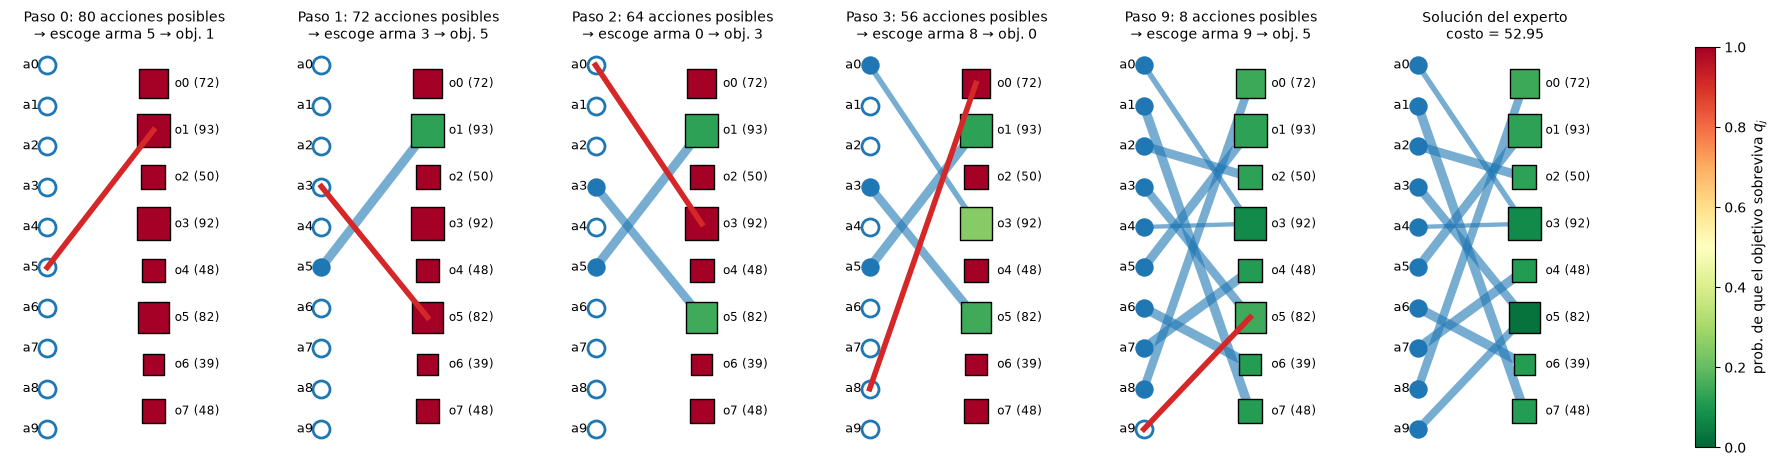

In [9]:
def plot_partial(inst, assignment, chosen=None, title="", ax=None, labels=True):
    # grafo bipartito armas (izq.) -> objetivos (der.). Azul: pares ya asignados; rojo: acción escogida.
    # Tamaño del objetivo ~ valor V_j; color ~ prob. de sobrevivir q_j. Círculo vacío = arma libre.
    if ax is None:
        fig, ax = plt.subplots(figsize=(4.2, 5))
    W, T = inst.n_weapons, inst.n_targets
    q = np.ones(T)
    for i, j in enumerate(assignment):
        if j >= 0:
            q[j] *= 1 - inst.probs[i, j]
    yw, yt = np.linspace(1, 0, W), np.linspace(0.95, 0.05, T)
    for i, j in enumerate(assignment):
        if j >= 0:
            ax.plot([0, 1], [yw[i], yt[j]], color="tab:blue", alpha=0.6,
                    lw=1 + 6 * (inst.probs[i, j] - 0.6) / 0.3, zorder=1)
    if chosen is not None:
        i, j = chosen
        ax.plot([0, 1], [yw[i], yt[j]], color="tab:red", lw=4, zorder=3)
    used = np.array([j >= 0 for j in assignment])
    ax.scatter(np.zeros(W)[used], yw[used], s=150, c="tab:blue", zorder=2)
    ax.scatter(np.zeros(W)[~used], yw[~used], s=150, facecolors="white", edgecolors="tab:blue", lw=2, zorder=2)
    sc = ax.scatter(np.ones(T), yt, s=inst.values * 6, c=q, cmap="RdYlGn_r", vmin=0, vmax=1,
                    marker="s", edgecolors="k", zorder=2)
    if labels:
        for i in range(W): ax.text(-0.08, yw[i], f"a{i}", ha="right", va="center", fontsize=9)
        for j in range(T): ax.text(1.2, yt[j], f"o{j} ({inst.values[j]:.0f})", ha="left", va="center", fontsize=8.5)
    ax.set_title(title, fontsize=10)
    ax.set_xlim(-0.35, 1.8); ax.set_ylim(-0.05, 1.05); ax.axis("off")
    return sc


show = [0, 1, 2, 3, len(demo_steps) - 1]
fig, axes = plt.subplots(1, len(show) + 1, figsize=(22, 5.2))
for ax, k in zip(axes, show):
    st, actions, chosen = demo_steps[k]
    plot_partial(inst_demo, st.assignment, chosen[1], ax=ax,
                 title=f"Paso {k}: {len(actions)} acciones posibles\n→ escoge arma {chosen[1][0]} → obj. {chosen[1][1]}")
sc = plot_partial(inst_demo, sol_ils, ax=axes[-1], title=f"Solución del experto\ncosto = {cost_ils:.2f}")
fig.colorbar(sc, ax=axes, fraction=0.012, label="prob. de que el objetivo sobreviva $q_j$")
guardar(fig, "descomposicion"); plt.show()

**Ejemplo visual de un estado y su acción** (para la introducción de la presentación): a la izquierda, los datos de la instancia (probabilidades $p_{ij}$ y valores $V_j$); a la derecha, el estado del paso 2 de la descomposición, las acciones posibles (todas las líneas grises: cada arma libre con cada objetivo) y la acción que escoge el experto (rojo).

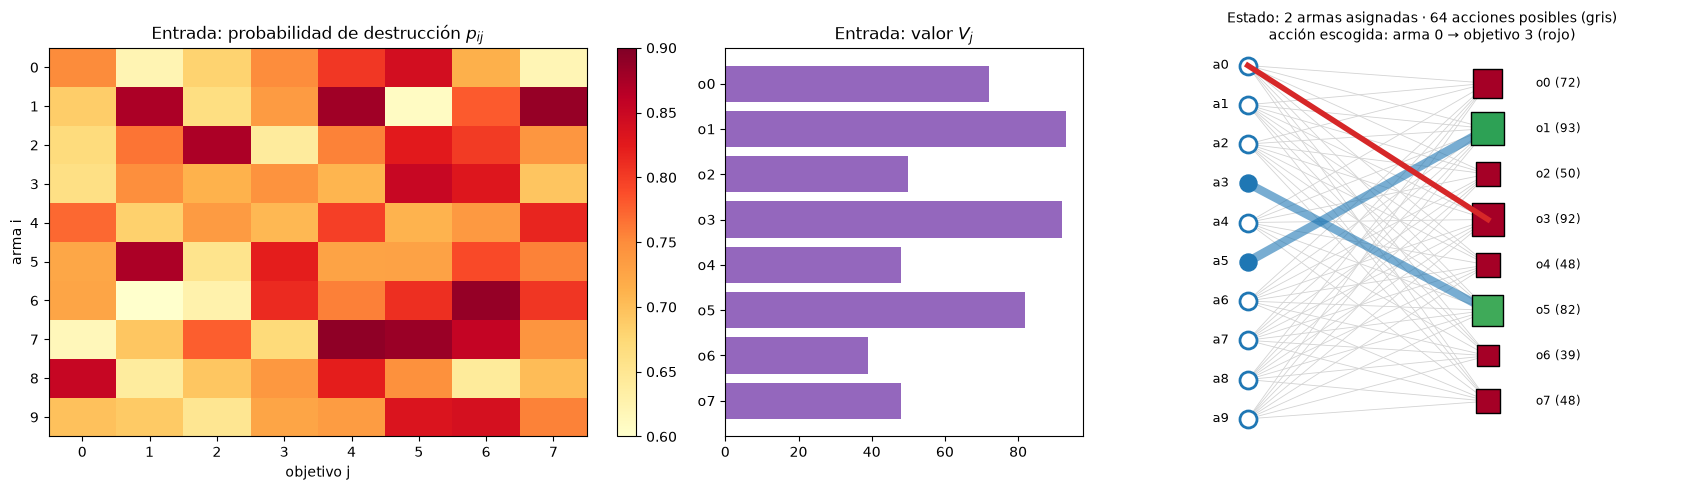

In [10]:
K_EJ = 2
st_ej, actions_ej, chosen_ej = demo_steps[K_EJ]
fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1.5, 0.9, 1.3]})
im = axes[0].imshow(inst_demo.probs, cmap="YlOrRd", vmin=0.6, vmax=0.9, aspect="auto")
axes[0].set_xlabel("objetivo j"); axes[0].set_ylabel("arma i")
axes[0].set_xticks(range(N_TARGETS)); axes[0].set_yticks(range(N_WEAPONS))
axes[0].set_title("Entrada: probabilidad de destrucción $p_{ij}$")
plt.colorbar(im, ax=axes[0], fraction=0.046)
axes[1].barh(range(N_TARGETS), inst_demo.values, color="tab:purple")
axes[1].invert_yaxis(); axes[1].set_yticks(range(N_TARGETS)); axes[1].set_yticklabels([f"o{j}" for j in range(N_TARGETS)])
axes[1].set_title("Entrada: valor $V_j$")
W_, T_ = N_WEAPONS, N_TARGETS
yw, yt = np.linspace(1, 0, W_), np.linspace(0.95, 0.05, T_)
for i in st_ej.free_weapons:
    for j in range(T_):
        axes[2].plot([0, 1], [yw[i], yt[j]], color="lightgray", lw=0.6, zorder=0)
plot_partial(inst_demo, st_ej.assignment, chosen_ej[1], ax=axes[2],
             title=f"Estado: {W_ - len(st_ej.free_weapons)} armas asignadas · {len(actions_ej)} acciones posibles (gris)\n"
                   f"acción escogida: arma {chosen_ej[1][0]} → objetivo {chosen_ej[1][1]} (rojo)")
plt.tight_layout(); guardar(fig, "instancia_estado_accion"); plt.show()

## 5. Representación del estado y features (`state2vec`)

Como en el notebook del TSP, la entrada **no se aplana**: es una matriz de forma `(n, VEC_LEN)` con `n = 1 + W·T` y `VEC_LEN = 16`.

- **Fila 0 — fila global** (tipo `[CLS]`): resume el estado completo. El modelo la identifica por el flag `es_global` (y además está siempre en la posición 0, como la ciudad inicial del TSP). Nunca es una acción válida.
- **Fila $1 + i \cdot T + j$ — par (arma $i$ → objetivo $j$)**: describe a la vez el estado y la acción "asignar el arma $i$ al objetivo $j$". La fila de un par es siempre la misma durante el episodio.

| # | Columna | Rol | Contenido | ¿Por qué ayuda a decidir? |
|---|---|---|---|---|
| 0 | `p_ij` | propia | $p_{ij}$ | efectividad del arma contra el objetivo |
| 1 | `valor` | propia | $V_j / \max V$ | importancia del objetivo |
| 2 | `p_vs_mejor` | propia | $p_{ij} - \max_{j'} p_{ij'}$ | ¿es $j$ el mejor destino posible para el arma $i$? (≤ 0) |
| 3 | `es_global` | **flag (query)** | 1 solo en la fila 0 | marca la fila que construye la query de decisión |
| 4 | `no_disponible` | **flag (máscara)** | 1 si el arma $i$ ya fue asignada, o si es la fila global | esas filas reciben logit $-10^9$ |
| 5 | `asignado` | flag | 1 si $x_{ij} = 1$ en la solución parcial | contexto: qué pares ya se eligieron |
| 6 | `q_sobrevive` | relativa | $q_j$ | cuánto queda por destruir en $j$ |
| 7 | `valor_en_juego` | relativa | $V_j q_j / \max V$ (fila global: $\sum V q / \sum V$) | valor que aún se puede ganar en $j$ |
| 8 | `ganancia` ⭐ | relativa | $g_{ij} / \max g$ sobre pares disponibles | **criterio de MMR** (el análogo de `dist_a_actual` del TSP) |
| 9 | `es_mmr` | relativa | 1 si es el par que elegiría MMR | la elección de la heurística clásica |
| 10 | `armas_en_obj` | relativa | nº de armas ya asignadas a $j$ / W | rendimientos decrecientes |
| 11 | `ventaja` | relativa | $p_{ij}$ − media de $p_{i'j}$ de las armas libres | ¿es esta arma comparativamente buena para $j$? |
| 12 | `arrepentimiento` | relativa | $(g_{ij} - \max_{i' \neq i \text{ libre}} g_{i'j}) / \max g$ | ¿otra arma libre aprovecharía mejor a $j$? |
| 13 | `mmr_completa` ⭐ | relativa | 1 si al completar con MMR desde este estado el arma $i$ va a $j$ | anticipación: mira las decisiones futuras |
| 14 | `q_final_mmr` | relativa | $q_j$ al completar con MMR | ¿quedará $j$ bien cubierto al final? |
| 15 | `frac_restantes` | global | armas libres / W (repetida en todas las filas) | etapa de la construcción |

Las características relativas se calculan solo para pares **disponibles** (armas libres); en las filas enmascaradas valen 0. Todas están normalizadas **por instancia** (divididas por el máximo o expresadas como fracción), así que su escala no depende de W ni de T y ningún peso del modelo depende del índice de la fila. La información de "qué arma es mejor para qué objetivo" también puede cruzarse entre filas vía self-attention: el par $(i, j)$ puede mirar a los pares $(i', j)$ de las otras armas.

In [11]:
FEATURES = ["p_ij", "valor", "p_vs_mejor", "es_global", "no_disponible", "asignado",
            "q_sobrevive", "valor_en_juego", "ganancia", "es_mmr", "armas_en_obj", "ventaja",
            "arrepentimiento", "mmr_completa", "q_final_mmr", "frac_restantes"]
VEC_LEN = len(FEATURES)                     # 16
COL_GLOBAL = FEATURES.index("es_global")    # 3: fila que forma la query de decisión
COL_MASK = FEATURES.index("no_disponible")  # 4: filas que no son acciones válidas
ROLE = ["propia"] * 3 + ["flag"] * 3 + ["relativa"] * 10


def mmr_completion(V, P, q, free):
    # completa la solución con MMR desde el estado actual: {arma libre: objetivo} y q final
    q = q.copy(); free = list(free); target = {}
    while free:
        gains = (V * q)[None, :] * P[free]
        r, j = np.unravel_index(np.argmax(gains), gains.shape)
        i = free.pop(r); q[j] *= 1 - P[i, j]; target[i] = int(j)
    return target, q


def state2vec(state):
    """Codifica un estado del WTAP como una matriz (1 + W·T, 16).
    Fila 0 = fila global; fila 1 + i·T + j = par (arma i -> objetivo j)."""
    inst = state.inst_info
    V, P = inst.values, inst.probs
    W, T = P.shape
    a = np.asarray(state.assignment)
    q, vmax = state.q, V.max()
    free = a < 0
    fw, done = np.flatnonzero(free), np.flatnonzero(~free)      # armas libres / ya asignadas
    F = np.zeros((W, T, VEC_LEN))

    # 1) características propias del par
    F[:, :, 0] = P
    F[:, :, 1] = V[None, :] / vmax
    F[:, :, 2] = P - P.max(1, keepdims=True)
    # 2) flags de estado
    F[:, :, 4] = (~free)[:, None]                               # máscara: el arma ya no está disponible
    F[done, a[done], 5] = 1                                     # pares de la solución parcial
    # 3) características relativas al estado
    F[:, :, 6] = q[None, :]
    F[:, :, 7] = (V * q / vmax)[None, :]
    F[:, :, 10] = (np.bincount(a[done], minlength=T) / W)[None, :]
    F[:, :, 15] = len(fw) / W
    if len(fw):
        gain = (V * q)[None, :] * P[fw]                         # ganancia de MMR, (armas libres, T)
        gmax = gain.max()
        F[fw, :, 8] = gain / gmax
        r, j = np.unravel_index(np.argmax(gain), gain.shape)
        F[fw[r], j, 9] = 1
        F[fw, :, 11] = P[fw] - P[fw].mean(0, keepdims=True)
        if len(fw) > 1:                                         # mejor ganancia de OTRA arma libre en j
            srt = np.sort(gain, axis=0)
            other = np.where(gain >= srt[-1][None, :], srt[-2][None, :], srt[-1][None, :])
        else:
            other = np.zeros_like(gain)
        F[fw, :, 12] = (gain - other) / gmax
        target, q_mmr = mmr_completion(V, P, q, fw)             # anticipación: completar con MMR
        for i, j in target.items():
            F[i, j, 13] = 1
        F[:, :, 14] = q_mmr[None, :]

    g = np.zeros(VEC_LEN)                                       # fila global
    g[COL_GLOBAL], g[COL_MASK] = 1, 1
    g[7] = V @ q / V.sum()
    g[15] = len(fw) / W
    return np.concatenate([g[None, :], F.reshape(W * T, VEC_LEN)]).astype(np.float32)

Veámoslo en el **paso 4** de la descomposición de la instancia de ejemplo (4 armas ya asignadas). Primero algunas filas; luego la matriz completa como mapa de calor (transpuesta: cada columna del gráfico es una fila de la matriz).

In [12]:
K_DEMO = 4
st_demo, actions_demo, chosen_demo = demo_steps[K_DEMO]
x_demo = state2vec(st_demo)
row_demo = 1 + chosen_demo[1][0] * N_TARGETS + chosen_demo[1][1]
print("Estado:", st_demo.assignment, "| forma de state2vec:", x_demo.shape)
print(f"El experto escoge arma {chosen_demo[1][0]} -> objetivo {chosen_demo[1][1]}  (fila {row_demo})\n")

def row_name(r, T=N_TARGETS):
    return "global" if r == 0 else f"a{(r - 1) // T}->o{(r - 1) % T}"

cols = [0, 3, 4, 5, 8, 9, 11, 12, 13, 15]
top = [0] + list(np.argsort(-x_demo[:, 8])[:6])
if row_demo not in top: top.append(row_demo)
print(f"{'fila':>12} | " + " ".join(f"{FEATURES[c][:10]:>10}" for c in cols))
print("-" * 125)
for r in top:
    mark = "  <- experto" if r == row_demo else ""
    print(f"{row_name(r):>12} | " + " ".join(f"{x_demo[r, c]:>10.2f}" for c in cols) + mark)

Estado: [3, -1, -1, 5, -1, 1, -1, -1, 0, -1] | forma de state2vec: (81, 16)
El experto escoge arma 2 -> objetivo 2  (fila 19)

        fila |       p_ij  es_global no_disponi   asignado   ganancia     es_mmr    ventaja arrepentim mmr_comple frac_resta
-----------------------------------------------------------------------------------------------------------------------------
      global |       0.00       1.00       1.00       0.00       0.00       0.00       0.00       0.00       0.00       0.60
      a2->o2 |       0.87       0.00       0.00       0.00       1.00       1.00       0.15       0.11       1.00       0.60  <- experto
      a7->o4 |       0.89       0.00       0.00       0.00       0.98       0.00       0.09       0.01       1.00       0.60
      a1->o7 |       0.89       0.00       0.00       0.00       0.97       0.00       0.09       0.08       1.00       0.60
      a1->o4 |       0.88       0.00       0.00       0.00       0.97       0.00       0.08      -0.01       0

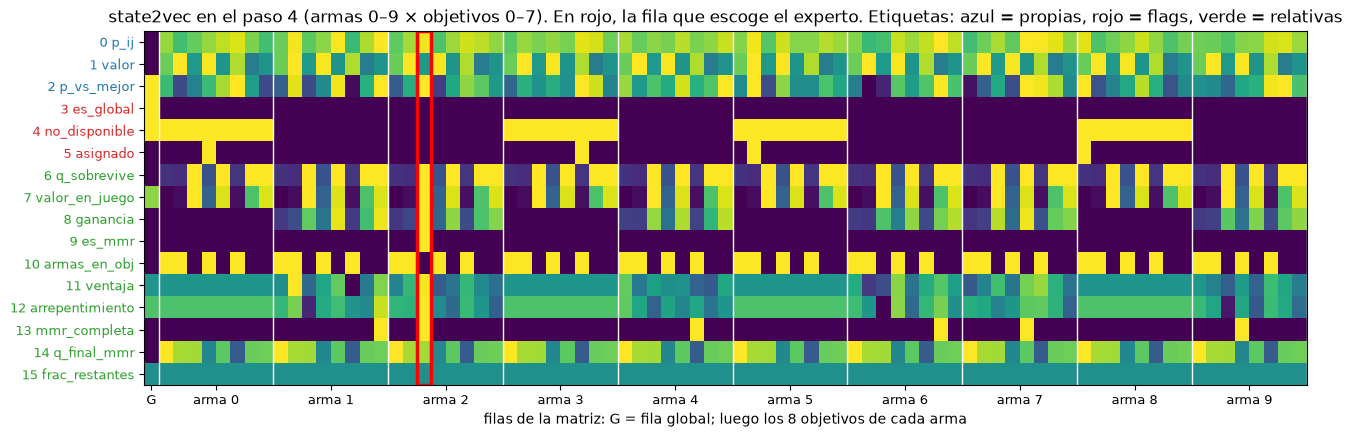

In [13]:
def plot_state_matrix(x, chosen_row, W, T, title=""):
    # muestra la matriz transpuesta; cada característica normalizada a [0, 1] solo para visualizar
    lo, hi = x.min(0), x.max(0)
    xs = np.where(hi > lo, (x - lo) / np.where(hi > lo, hi - lo, 1), 0.5)   # columnas constantes: color medio
    fig, ax = plt.subplots(figsize=(15, 4.6))
    ax.imshow(xs.T, cmap="viridis", aspect="auto", interpolation="nearest")
    for i in range(W + 1):
        ax.axvline(0.5 + i * T, color="white", lw=1)
    ax.set_xticks([0] + [1 + i * T + (T - 1) / 2 for i in range(W)])
    ax.set_xticklabels(["G"] + [f"arma {i}" for i in range(W)], fontsize=9)
    ax.set_yticks(range(VEC_LEN)); ax.set_yticklabels([f"{k:>2} {f}" for k, f in enumerate(FEATURES)], fontsize=9)
    colors = {"propia": "tab:blue", "flag": "tab:red", "relativa": "tab:green"}
    for lbl, role in zip(ax.get_yticklabels(), ROLE):
        lbl.set_color(colors[role])
    ax.add_patch(plt.Rectangle((chosen_row - 0.5, -0.5), 1, VEC_LEN, fill=False, ec="red", lw=2.5))
    ax.set_xlabel("filas de la matriz: G = fila global; luego los 8 objetivos de cada arma")
    ax.set_title(title)
    return fig

fig = plot_state_matrix(x_demo, row_demo, N_WEAPONS, N_TARGETS,
                        f"state2vec en el paso {K_DEMO} (armas 0–9 × objetivos 0–7). En rojo, la fila que escoge el experto. "
                        "Etiquetas: azul = propias, rojo = flags, verde = relativas")
guardar(fig, "estado"); plt.show()

## 6. Generación de datos (II): codificación de la salida y dataset

### Salida
El modelo entrega un **vector de logits de largo $n = 1 + W\cdot T$**, uno por fila; tras un softmax es la probabilidad de que cada fila sea la próxima acción.

- **Acción ↔ fila:** la acción `("constructive", (i, j))` es "elegir la fila $1 + i\cdot T + j$". Como cada fila ya es un par, no hace falta combinar dos elementos como en un 2-opt: el puntero selecciona el par directamente.
- **Máscara:** las filas con `no_disponible = 1` (columna 4) reciben logit $-10^9$ y probabilidad 0: la fila global y los T pares de cada arma ya asignada. Con $k$ armas libres quedan exactamente $k \cdot T$ filas válidas, las mismas acciones que genera `env.gen_actions`.
- **Etiqueta `Y`:** el índice (entero) de la fila escogida por el experto. Equivale a un vector one-hot de largo $n$, pero se guarda como entero para `CrossEntropyLoss`.

### Construcción del dataset
`generate_imitation_data` genera instancias aleatorias, las resuelve con el experto (ILS), descompone cada solución con `decompose` y transforma cada tupla en un par `(x, y) = (state2vec(estado), fila escogida)`. Además retorna las instancias resueltas para reutilizar el costo del experto en la evaluación.

- **Entrenamiento:** 6 000 instancias 10×8 (semilla 0) → 60 000 muestras.
- **Validación:** 300 instancias (semilla 1) → 3 000 muestras (early stopping y selección de configuración).
- **Prueba:** 50 instancias (semilla 2024), **las mismas de la Tarea 4**, para comparar directamente con la MLP.

In [14]:
def action2row(action, n_targets):
    i, j = action[1]
    return 1 + i * n_targets + j

def row2action(row, n_targets):
    return ("constructive", ((row - 1) // n_targets, (row - 1) % n_targets))


def solve_instances(n_weapons, n_targets, n_instances, seed):
    # genera instancias aleatorias y las resuelve con el experto (ILS)
    rng, rng_ils = np.random.RandomState(seed), np.random.default_rng(seed)
    solved = []
    for _ in range(n_instances):
        inst = WTAP_Instance.random(n_weapons, n_targets, rng=rng)
        expert_assignment, expert_cost = ils(inst, rng=rng_ils)
        solved.append((inst, expert_assignment, expert_cost))
    return solved


def generate_imitation_data(n_weapons=N_WEAPONS, n_targets=N_TARGETS, n_instances=100, seed=0):
    solved = solve_instances(n_weapons, n_targets, n_instances, seed)       # 1-2. instancias + experto
    X, Y = [], []
    for inst, expert_assignment, _ in solved:
        for state, actions, chosen in decompose(inst, expert_assignment):  # 3. tuplas paso a paso
            X.append(state2vec(state))                                     # 4. x = state2vec(estado)
            Y.append(action2row(chosen, n_targets))                        #    y = fila escogida
    return torch.tensor(np.stack(X)), torch.tensor(Y, dtype=torch.long), solved


t0 = time.time()
X_train, Y_train, train_solved = generate_imitation_data(N_WEAPONS, N_TARGETS, n_instances=6000, seed=0)
X_val,   Y_val,   val_solved   = generate_imitation_data(N_WEAPONS, N_TARGETS, n_instances=300,  seed=1)
X_test,  Y_test,  test_solved  = generate_imitation_data(N_WEAPONS, N_TARGETS, n_instances=50,   seed=2024)
print(f"Datos generados en {time.time() - t0:.0f} s\n")
print("X_train:", tuple(X_train.shape), "-> (muestras, 1 + W·T filas, VEC_LEN)")
print("Y_train:", tuple(Y_train.shape), "-> fila escogida por el experto")
print("X_val:  ", tuple(X_val.shape), "| Y_val:", tuple(Y_val.shape))
print("X_test: ", tuple(X_test.shape), "| Y_test:", tuple(Y_test.shape))
test_expert = np.array([c for _, _, c in test_solved])
print(f"\nCosto medio del experto en las 50 instancias de prueba: {test_expert.mean():.3f} (Tarea 4: 46.263)")

Datos generados en 147 s

X_train: (60000, 81, 16) -> (muestras, 1 + W·T filas, VEC_LEN)
Y_train: (60000,) -> fila escogida por el experto
X_val:   (3000, 81, 16) | Y_val: (3000,)
X_test:  (500, 81, 16) | Y_test: (500,)

Costo medio del experto en las 50 instancias de prueba: 46.263 (Tarea 4: 46.263)


**Sanity check.** Mostramos la matriz `state2vec` completa de una muestra, su fila escogida y verificamos que **no** esté enmascarada. Luego comprobamos lo mismo en *todas* las muestras, además de que haya exactamente una fila global por estado y que el número de filas válidas sea (armas libres)·T.

In [15]:
k = 4                                    # quinta decisión de la primera instancia de entrenamiento
x, y = X_train[k].numpy(), Y_train[k].item()
print("Columnas:", ", ".join(f"{c}={f}" for c, f in enumerate(FEATURES)), "\n")
print(f"{'fila':>4} {'':>8} " + " ".join(f"{c:>5}" for c in range(VEC_LEN)))
for r in range(x.shape[0]):
    print(f"{r:>4} {row_name(r):>8} " + " ".join(f"{v:>5.2f}" for v in x[r]) + ("   <-- fila escogida" if r == y else ""))
print(f"\nFila escogida: {y} = {row2action(y, N_TARGETS)} | no_disponible = {x[y, COL_MASK]:.0f}")
assert x[y, COL_MASK] == 0

for name, X, Y in [("train", X_train, Y_train), ("val", X_val, Y_val), ("test", X_test, Y_test)]:
    assert (X[torch.arange(len(Y)), Y, COL_MASK] == 0).all()             # la fila escogida nunca está enmascarada
    assert ((X[:, :, COL_GLOBAL] == 1).sum(1) == 1).all()                # una fila global por estado
    free = X[:, 0, 15] * N_WEAPONS                                       # frac_restantes · W
    assert torch.allclose((X[:, :, COL_MASK] == 0).sum(1).float(), free * N_TARGETS)
print("✔ En train/val/test: la fila escogida nunca está enmascarada, hay una fila global por estado "
      "y las filas válidas son (armas libres)·T")

Columnas: 0=p_ij, 1=valor, 2=p_vs_mejor, 3=es_global, 4=no_disponible, 5=asignado, 6=q_sobrevive, 7=valor_en_juego, 8=ganancia, 9=es_mmr, 10=armas_en_obj, 11=ventaja, 12=arrepentimiento, 13=mmr_completa, 14=q_final_mmr, 15=frac_restantes 

fila              0     1     2     3     4     5     6     7     8     9    10    11    12    13    14    15
   0   global  0.00  0.00  0.00  1.00  1.00  0.00  0.00  0.46  0.00  0.00  0.00  0.00  0.00  0.00  0.00  0.60
   1   a0->o0  0.69  0.75 -0.16  0.00  1.00  0.00  1.00  0.75  0.00  0.00  0.00  0.00  0.00  0.00  0.13  0.60
   2   a0->o1  0.62  0.78 -0.23  0.00  1.00  0.00  0.10  0.08  0.00  0.00  0.10  0.00  0.00  0.00  0.10  0.60
   3   a0->o2  0.68  0.97 -0.17  0.00  1.00  0.00  0.14  0.13  0.00  0.00  0.10  0.00  0.00  0.00  0.03  0.60
   4   a0->o3  0.74  1.00 -0.11  0.00  1.00  0.00  0.11  0.11  0.00  0.00  0.10  0.00  0.00  0.00  0.11  0.60
   5   a0->o4  0.84  1.00 -0.01  0.00  1.00  1.00  0.16  0.16  0.00  0.00  0.10  0.00  0.00  0.00  0

## 7. Arquitectura: encoder + decoder (`WTAP_Attention`)

El modelo se divide en un **encoder**, que contextualiza la secuencia de filas, y un **decoder**, que convierte el estado en una distribución sobre las acciones:

| | Qué entra | Qué hace | Qué sale |
|---|---|---|---|
| **Encoder** | la secuencia de $n = 1 + W\cdot T$ filas de `state2vec` (16 features cada una) | embedding lineal compartido $16 \to 64$ y **2 capas** de self-attention (1 cabeza) + feed-forward $64\to128\to64$, con residual y LayerNorm | $H \in \mathbb{R}^{n \times 64}$: un embedding contextualizado por fila (cada par "sabe" de los demás pares y del estado global) |
| **Decoder** | $H$, el flag `es_global` (col. 3) y la máscara `no_disponible` (col. 4) | arma el **contexto** $[h_{\text{global}} ; \bar h_{\text{disp}}]$, lo proyecta a una query $q$ y calcula la compatibilidad $q\cdot h_r/\sqrt d$ con cada fila (**puntero**), enmascarando las filas no disponibles | **distribución de probabilidad** sobre las $n$ filas = sobre las acciones (softmax) |

Como las features incluyen el estado (qué armas están libres, $q_j$, anticipación MMR), el encoder se vuelve a ejecutar en **cada paso** de la construcción. En el modelo de Kool et al. (2019), en cambio, el encoder corre una vez por instancia y el estado entra solo al decoder, que además hace un **glimpse** (una atención multi-cabeza del contexto sobre $H$) antes del puntero. Nuestro decoder es la versión sin glimpse: 1 capa de decisión con una sola cabeza.

La estructura es la de `TSP_Attention`: **embedding compartido → self-attention con residual → feed-forward → query de decisión → puntero con máscara**. Lo que cambia:

| | `TSP_Attention` | `WTAP_Attention` |
|---|---|---|
| Filas de la entrada | ciudades | fila global + pares (arma, objetivo) |
| `VEC_LEN` | 6 | 16 |
| Encoder | 1 bloque, sin normalización | 2 bloques con **LayerNorm** y **Dropout** (el correo advierte que al imitar trayectorias exactas el modelo se sobreajusta fácilmente) |
| **Query de decisión** (paso 3) | $q = W_c[h_{\text{actual}} ; h_{\text{inicial}}]$ con `es_actual` (col. 2) y la fila 0 | $q = W_c[h_{\text{global}} ; \bar h_{\text{disp}}]$: la fila marcada con `es_global` (col. 3) y el **promedio de las filas disponibles** |
| **Máscara** (paso 4) | `visitada` (col. 3) | `no_disponible` (col. 4) |
| Puntero | $u_i = (W_Q^{ptr} q)\cdot(W_K^{ptr} h_i)/\sqrt d$ | igual |

En el WTAP no hay una "ciudad actual": el estado es la solución parcial completa. Por eso la query se arma con la **fila global**, que tras la self-attention resume todo el estado (como el token `[CLS]` de BERT), y con el **promedio de los pares aún disponibles** (el "embedding del grafo" de Kool et al., 2019, que el notebook del TSP sugiere como extensión). Mantenemos el tamaño moderado: $d = 64$ y 2 capas.

In [16]:
class EncoderBlock(nn.Module):
    # self-attention + feed-forward, ambos con conexión residual, LayerNorm y Dropout
    def __init__(self, d, dropout):
        super().__init__()
        self.d = d
        self.Wq = nn.Linear(d, d, bias=False)
        self.Wk = nn.Linear(d, d, bias=False)
        self.Wv = nn.Linear(d, d, bias=False)
        self.ff = nn.Sequential(nn.Linear(d, 2 * d), nn.ReLU(), nn.Linear(2 * d, d))
        self.norm1, self.norm2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.drop = nn.Dropout(dropout)

    def forward(self, H):
        Q, K, V = self.Wq(H), self.Wk(H), self.Wv(H)
        A = torch.softmax(Q @ K.transpose(1, 2) / self.d ** 0.5, dim=-1)   # (batch, n, n)
        H = self.norm1(H + self.drop(A @ V))                                # residual
        H = self.norm2(H + self.drop(self.ff(H)))                           # residual
        return H


class WTAP_Attention(nn.Module):
    def __init__(self, vec_len=VEC_LEN, d=64, n_layers=2, dropout=0.1):
        super().__init__()
        self.d = d
        # --- Encoder ---
        self.embed   = nn.Linear(vec_len, d)                               # embedding por fila (pesos compartidos)
        self.encoder = nn.ModuleList([EncoderBlock(d, dropout) for _ in range(n_layers)])
        # --- Decisión ---
        self.Wc     = nn.Linear(2 * d, d)                                  # [h_global ; promedio disponibles] -> q
        self.Wq_ptr = nn.Linear(d, d, bias=False)                          # proyecciones del puntero
        self.Wk_ptr = nn.Linear(d, d, bias=False)

    def forward(self, x, return_probabilities=False):
        # x tiene forma (batch, 1 + W·T, VEC_LEN) -- W y T pueden ser cualesquiera
        if x.dim() == 2:
            x = x.unsqueeze(0)

        # 1. Embedding por fila (mismos pesos para todos los pares)
        H = self.embed(x)                                                   # (batch, n, d)

        # 2. Self-attention: cada par mira a todos los demás (2 bloques)
        for block in self.encoder:
            H = block(H)

        # 3. Query de decisión: fila global + promedio de los pares disponibles
        h_global = H[x[:, :, COL_GLOBAL] == 1]                              # el flag marca una fila por estado
        disp = (x[:, :, COL_MASK] == 0).float().unsqueeze(-1)               # (batch, n, 1)
        h_disp = (H * disp).sum(1) / disp.sum(1).clamp(min=1)
        q = self.Wc(torch.cat([h_global, h_disp], dim=-1))                  # (batch, d)

        # 4. Puntero: compatibilidad de q con cada fila -> un logit por fila
        u = (self.Wk_ptr(H) @ self.Wq_ptr(q).unsqueeze(-1)).squeeze(-1)     # (batch, n)
        u = u / self.d ** 0.5
        u = u.masked_fill(x[:, :, COL_MASK] == 1, -1e9)                     # máscara: filas no disponibles

        if return_probabilities:
            return torch.softmax(u, dim=-1)
        return u


torch.manual_seed(0)
model = WTAP_Attention()
print(model)
print("\nParámetros entrenables:", sum(p.numel() for p in model.parameters() if p.requires_grad))

WTAP_Attention(
  (embed): Linear(in_features=16, out_features=64, bias=True)
  (encoder): ModuleList(
    (0-1): 2 x EncoderBlock(
      (Wq): Linear(in_features=64, out_features=64, bias=False)
      (Wk): Linear(in_features=64, out_features=64, bias=False)
      (Wv): Linear(in_features=64, out_features=64, bias=False)
      (ff): Sequential(
        (0): Linear(in_features=64, out_features=128, bias=True)
        (1): ReLU()
        (2): Linear(in_features=128, out_features=64, bias=True)
      )
      (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (drop): Dropout(p=0.1, inplace=False)
    )
  )
  (Wc): Linear(in_features=128, out_features=64, bias=True)
  (Wq_ptr): Linear(in_features=64, out_features=64, bias=False)
  (Wk_ptr): Linear(in_features=64, out_features=64, bias=False)
)

Parámetros entrenables: 75776


**Validación del modelo (sin entrenar).** Verificamos, como en el notebook del TSP:
1. la salida tiene forma `(batch, n)` y cada fila suma 1;
2. las filas enmascaradas tienen probabilidad 0;
3. la query se construye con exactamente **una** fila global por estado;
4. el mismo modelo acepta, sin modificaciones, un estado de una instancia de **otro tamaño** (20 armas × 15 objetivos → 301 filas);
5. la `CrossEntropyLoss` se calcula sin errores sobre un mini-lote. Sin entrenar, las probabilidades son casi uniformes sobre las acciones válidas, así que la pérdida debe rondar $\overline{\log(\#\text{válidas})}$.

In [17]:
model.eval()
xb, yb = X_train[:16], Y_train[:16]
with torch.no_grad():
    probs = model(xb, return_probabilities=True)
print("1. Forma de la salida:", tuple(probs.shape), "-> (batch, 1 + W·T)")
print("   Suma de probabilidades por estado:", probs.sum(-1).numpy().round(4))
assert probs.shape == (16, 1 + N_WEAPONS * N_TARGETS) and torch.allclose(probs.sum(-1), torch.ones(16))

p_masked = probs[xb[:, :, COL_MASK] == 1].max().item()
print("2. Prob. máxima en filas enmascaradas (debe ser 0):", p_masked)
assert p_masked == 0

n_global = (xb[:, :, COL_GLOBAL] == 1).sum(1)
print("3. Filas globales por estado (debe ser 1):", n_global.tolist())
assert (n_global == 1).all()
with torch.no_grad():
    H = model.embed(xb)
    for block in model.encoder:
        H = block(H)
    print("   h_global:", tuple(H[xb[:, :, COL_GLOBAL] == 1].shape), "-> un vector de dimensión d por estado")

rng = np.random.RandomState(5)
inst20 = WTAP_Instance.random(20, 15, rng=rng)
state20 = WTAP_State(inst20)
for _ in range(3):                                   # 3 armas asignadas con MMR
    evals = evalConstructiveActions(state20, env)
    env.state_transition(state20, max(evals, key=lambda e: e[1])[0])
x20 = torch.tensor(state2vec(state20))
with torch.no_grad():
    probs20 = model(x20, return_probabilities=True)
print(f"4. Instancia 20×15: entrada {tuple(x20.shape)} -> salida {tuple(probs20.shape)}, "
      f"suma = {probs20.sum().item():.4f}, filas válidas con prob > 0: {(probs20 > 0).sum().item()} "
      f"(= 17 armas libres × 15)  -> ¡ningún peso depende de W ni de T!")
assert (probs20 > 0).sum().item() == 17 * 15

loss = nn.CrossEntropyLoss()(model(xb), yb)
ref = torch.log((xb[:, :, COL_MASK] == 0).sum(1).float()).mean()
print(f"5. CrossEntropyLoss sobre el mini-lote: {loss.item():.3f}  (referencia uniforme: {ref.item():.3f})")

1. Forma de la salida: (16, 81) -> (batch, 1 + W·T)
   Suma de probabilidades por estado: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
2. Prob. máxima en filas enmascaradas (debe ser 0): 0.0
3. Filas globales por estado (debe ser 1): [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
   h_global: (16, 64) -> un vector de dimensión d por estado
4. Instancia 20×15: entrada (301, 16) -> salida (1, 301), suma = 1.0000, filas válidas con prob > 0: 255 (= 17 armas libres × 15)  -> ¡ningún peso depende de W ni de T!
5. CrossEntropyLoss sobre el mini-lote: 3.731  (referencia uniforme: 3.769)


## 8. Configuración experimental, entrenamiento y convergencia

El ciclo es el del notebook: entropía cruzada, Adam, mini-lotes y **early stopping** sobre la pérdida de validación (se restauran los pesos de la mejor época). Lo escribimos como función.

**Selección de hiperparámetros.** En la Tarea 5 comparamos tres niveles de Dropout con este mismo pipeline y las mismas semillas, eligiendo por el **gap del rollout** en 100 instancias de validación (no de prueba). Aquí entrenamos la configuración ganadora y reportamos ese barrido como referencia.

In [18]:
def train_model(X_train, Y_train, X_val, Y_val, d=64, n_layers=2, dropout=0.1, batch_size=256, lr=1e-3,
                num_epochs=100, patience=8, min_delta=1e-3, seed=0, verbose=True):
    torch.manual_seed(seed)
    model = WTAP_Attention(vec_len=X_train.shape[2], d=d, n_layers=n_layers, dropout=dropout).to(device)
    loader = DataLoader(TensorDataset(X_train, Y_train), batch_size=batch_size, shuffle=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    Xv, Yv = X_val.to(device), Y_val.to(device)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss, best_weights, best_epoch, epochs_no_improve = float("inf"), None, 0, 0
    for epoch in range(num_epochs):
        model.train()
        train_loss, train_hits = 0.0, 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()                  # 1. borrar gradientes
            logits = model(xb)                     # 2. forward
            loss = criterion(logits, yb)           # 3. pérdida
            loss.backward()                        # 4. backward
            optimizer.step()                       # 5. actualizar pesos
            train_loss += loss.item() * xb.size(0)
            train_hits += (logits.argmax(-1) == yb).sum().item()
        train_loss /= len(loader.dataset); train_acc = train_hits / len(loader.dataset)

        model.eval()
        with torch.no_grad():
            val_logits = torch.cat([model(Xv[s:s + 1024]) for s in range(0, len(Xv), 1024)])
            val_loss = criterion(val_logits, Yv).item()
            val_acc = (val_logits.argmax(-1) == Yv).float().mean().item()
        for key, value in zip(history, [train_loss, val_loss, train_acc, val_acc]):
            history[key].append(value)
        if verbose and epoch % 5 == 0:
            print(f"Época {epoch:3d} | loss train: {train_loss:.3f} | loss val: {val_loss:.3f} "
                  f"| acc train: {train_acc:.3f} | acc val: {val_acc:.3f}")

        if val_loss < best_val_loss - min_delta:
            best_val_loss, best_epoch, epochs_no_improve = val_loss, epoch, 0
            best_weights = copy.deepcopy(model.state_dict())
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                if verbose:
                    print(f"⏹ Early stopping en época {epoch}. Mejor época: {best_epoch} "
                          f"| loss val: {best_val_loss:.3f} | acc val: {history['val_acc'][best_epoch]:.3f}")
                break
    model.load_state_dict(best_weights)
    history["best_epoch"] = best_epoch
    return model.cpu(), history

Para medir el gap del rollout necesitamos el agente, que se define en detalle en la sección 9. `ModelEvalActions` es el del notebook del TSP, pero indexa las probabilidades con la fila del par: `predictions[k][1 + i·T + j]`.

In [19]:
class ModelEvalActions():
    def __init__(self, model):
        self.model = model

    def __call__(self, states, env):
        single_state = not isinstance(states, list)
        if single_state:
            states = [states]
        pending = [k for k, s in enumerate(states) if not s.is_complete]
        evals = [[] for _ in states]
        if pending:
            vecs = np.stack([state2vec(states[k]) for k in pending])     # mismo tamaño dentro de un lote
            self.model.eval()
            with torch.no_grad():
                predictions = self.model(torch.tensor(vecs), return_probabilities=True)
            for row, k in enumerate(pending):
                T = states[k].inst_info.n_targets
                evals[k] = [(action, predictions[row][action2row(action, T)].item())
                            for action in env.gen_actions(states[k], "constructive")]
        return evals[0] if single_state else evals


def rollout_costs(eval_actions, instances):
    # construye soluciones completas para muchas instancias en paralelo con el agente greedy
    solver = SingleAgentSolver(env, GreedyAgent(eval_actions))
    final_states, *_ = solver.multistate_solve([WTAP_State(inst) for inst in instances])
    assert all(s.is_complete for s in final_states)
    return np.array([s.cost for s in final_states])


def gap(costs, expert_costs):
    return 100 * (np.asarray(costs) / np.asarray(expert_costs) - 1)


val_insts = [inst for inst, _, _ in val_solved[:100]]
val_expert = np.array([c for _, _, c in val_solved[:100]])
gap_mmr_val = gap(rollout_costs(evalConstructiveActions, val_insts), val_expert).mean()
print(f"Referencia en 100 instancias de validación -> MMR: gap = {gap_mmr_val:.2f}%")

Referencia en 100 instancias de validación -> MMR: gap = 6.94%


In [20]:
# barrido de Dropout de la Tarea 5 (mismo pipeline, mismas semillas, 100 instancias de validación)
DROPOUT_SWEEP_T5 = {0.0: {"acc_val": 0.873, "gap_val": 3.35},
                    0.1: {"acc_val": 0.872, "gap_val": 3.51},
                    0.2: {"acc_val": 0.862, "gap_val": 3.90}}
print("Barrido de Dropout (Tarea 5):")
for dp, r in DROPOUT_SWEEP_T5.items():
    print(f"  Dropout {dp:.1f}: acc val = {r['acc_val']:.3f} | gap rollout val = {r['gap_val']:.2f}%")

configs = [
    # nombre,                                  hiperparámetros de train_model
    ("d=64, 2 capas, 1 cabeza, sin Dropout",  dict(d=64, n_layers=2, dropout=0.0)),
]

experiments = {}
for name, cfg in configs:
    t0 = time.time()
    print(f"\n--- {name} ---")
    m, h = train_model(X_train, Y_train, X_val, Y_val, **cfg)
    costs = rollout_costs(ModelEvalActions(m), val_insts)
    experiments[name] = {"model": m, "history": h, "config": cfg, "train_time": time.time() - t0,
                         "val_acc": h["val_acc"][h["best_epoch"]], "val_loss": h["val_loss"][h["best_epoch"]],
                         "gap": gap(costs, val_expert).mean(),
                         "params": sum(p.numel() for p in m.parameters())}
    print(f"==> acc val = {experiments[name]['val_acc']:.3f} | gap rollout val = {experiments[name]['gap']:.2f}% "
          f"(MMR: {gap_mmr_val:.2f}%) | épocas = {len(h['val_loss'])} | {time.time() - t0:.0f} s")

best_name = min(experiments, key=lambda n: experiments[n]["gap"])
best = experiments[best_name]
model, history = best["model"], best["history"]

Barrido de Dropout (Tarea 5):
  Dropout 0.0: acc val = 0.873 | gap rollout val = 3.35%
  Dropout 0.1: acc val = 0.872 | gap rollout val = 3.51%
  Dropout 0.2: acc val = 0.862 | gap rollout val = 3.90%

--- d=64, 2 capas, 1 cabeza, sin Dropout ---


Época   0 | loss train: 0.621 | loss val: 0.468 | acc train: 0.802 | acc val: 0.823


Época   5 | loss train: 0.397 | loss val: 0.398 | acc train: 0.847 | acc val: 0.844


Época  10 | loss train: 0.368 | loss val: 0.360 | acc train: 0.855 | acc val: 0.856


Época  15 | loss train: 0.356 | loss val: 0.367 | acc train: 0.858 | acc val: 0.855


...

Época  45 | loss train: 0.318 | loss val: 0.342 | acc train: 0.873 | acc val: 0.857


Época  50 | loss train: 0.314 | loss val: 0.330 | acc train: 0.874 | acc val: 0.865


Época  55 | loss train: 0.309 | loss val: 0.323 | acc train: 0.876 | acc val: 0.869


⏹ Early stopping en época 56. Mejor época: 48 | loss val: 0.313 | acc val: 0.873


==> acc val = 0.873 | gap rollout val = 3.35% (MMR: 6.94%) | épocas = 57 | 1161 s


### Configuración experimental (todos los hiperparámetros)

In [21]:
cfg = best["config"]
HPARAMS = {
    "Arquitectura": {
        "Capas del encoder": "2 (self-attention + feed-forward)",
        "Capas del decoder": "1 (query de contexto + puntero, sin glimpse)",
        "Cabezas de atención (MHA)": "1",
        "Dimensión de los embeddings d": str(cfg["d"]),
        "Feed-forward": f"{cfg['d']} → {2 * cfg['d']} → {cfg['d']} (ReLU)",
        "Normalización": "LayerNorm después de cada residual",
        "Dropout": f"{cfg['dropout']} (barrido 0 / 0,1 / 0,2 en la Tarea 5)",
        "Parámetros entrenables": f"{best['params']:,}".replace(",", " "),
    },
    "Entrenamiento": {
        "Split entrenamiento / validación": f"{len(train_solved)} / {len(val_solved)} instancias "
                                            f"({len(Y_train):,} / {len(Y_val):,} pares estado-acción)".replace(",", " "),
        "Conjunto de prueba (aparte)": f"{len(test_solved)} instancias 10×8 (las mismas de la Tarea 4)",
        "Épocas": f"máx. 100; early stopping en la época {len(history['val_loss']) - 1} (mejor: {history['best_epoch']})",
        "Batch size": "256",
        "Optimizador y tasa de aprendizaje": "Adam, lr = 1e-3",
        "Scheduler": "no se usó",
        "Early stopping": "pérdida de validación, paciencia 8, min_delta 1e-3; restaura la mejor época",
        "Función de pérdida": "CrossEntropyLoss sobre logits enmascarados (−1e9 en filas no disponibles)",
        "Métrica de validación": "pérdida (early stopping); accuracy y gap del rollout (selección)",
        "Tiempo de entrenamiento": f"{best['train_time'] / 60:.1f} min en {device}",
    },
}
for group, rows in HPARAMS.items():
    print(f"\n{group}")
    for k, v in rows.items():
        print(f"  {k:<36} {v}")


Arquitectura
  Capas del encoder                    2 (self-attention + feed-forward)
  Capas del decoder                    1 (query de contexto + puntero, sin glimpse)
  Cabezas de atención (MHA)            1
  Dimensión de los embeddings d        64
  Feed-forward                         64 → 128 → 64 (ReLU)
  Normalización                        LayerNorm después de cada residual
  Dropout                              0.0 (barrido 0 / 0,1 / 0,2 en la Tarea 5)
  Parámetros entrenables               75 776

Entrenamiento
  Split entrenamiento / validación     6000 / 300 instancias (60 000 / 3 000 pares estado-acción)
  Conjunto de prueba (aparte)          50 instancias 10×8 (las mismas de la Tarea 4)
  Épocas                               máx. 100; early stopping en la época 56 (mejor: 48)
  Batch size                           256
  Optimizador y tasa de aprendizaje    Adam, lr = 1e-3
  Scheduler                            no se usó
  Early stopping                       pérdida de

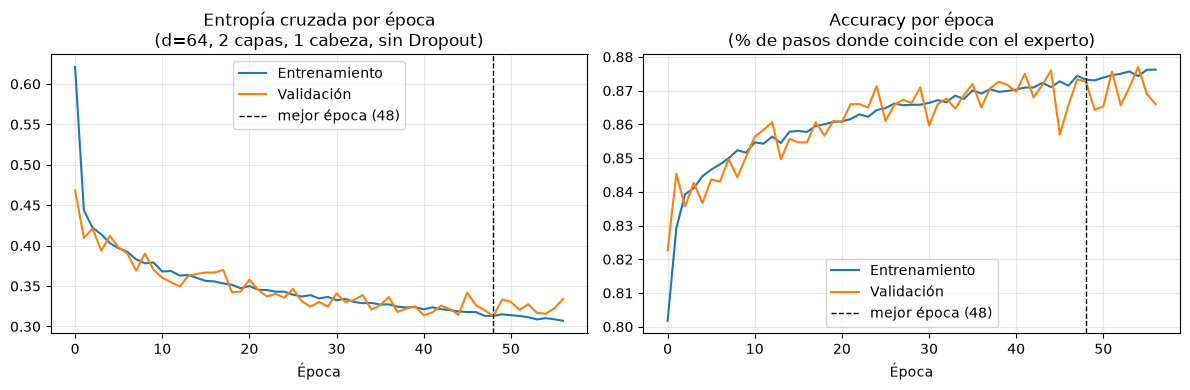

In [22]:
def plot_history(history, title_suffix=""):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    ep = np.arange(len(history["train_loss"])); b = history["best_epoch"]
    axes[0].plot(ep, history["train_loss"], label="Entrenamiento")
    axes[0].plot(ep, history["val_loss"], label="Validación")
    axes[0].set_title("Entropía cruzada por época" + title_suffix); axes[0].set_xlabel("Época")
    axes[1].plot(ep, history["train_acc"], label="Entrenamiento")
    axes[1].plot(ep, history["val_acc"], label="Validación")
    axes[1].set_title("Accuracy por época\n(% de pasos donde coincide con el experto)"); axes[1].set_xlabel("Época")
    for ax in axes:
        ax.axvline(b, color="k", ls="--", lw=1, label=f"mejor época ({b})")
        ax.grid(alpha=0.3); ax.legend()
    plt.tight_layout()
    return fig

fig = plot_history(history, f"\n({best_name})"); guardar(fig, "curvas"); plt.show()

**¿Hubo sobreajuste?** Comparamos la pérdida de entrenamiento y la de validación en la mejor época y al final. Si el modelo memorizara las trayectorias del experto, la pérdida de entrenamiento seguiría bajando mientras la de validación sube; una diferencia cercana a cero indica que no hay sobreajuste.

In [23]:
b = history["best_epoch"]
conv = {"best_epoch": b, "epochs": len(history["val_loss"]),
        "train_loss_best": history["train_loss"][b], "val_loss_best": history["val_loss"][b],
        "train_loss_last": history["train_loss"][-1], "val_loss_last": history["val_loss"][-1],
        "train_acc_best": history["train_acc"][b], "val_acc_best": history["val_acc"][b]}
print(f"Mejor época {b}: loss train = {conv['train_loss_best']:.3f} | loss val = {conv['val_loss_best']:.3f} "
      f"| diferencia val − train = {conv['val_loss_best'] - conv['train_loss_best']:+.3f}")
print(f"Última época {conv['epochs'] - 1}: loss train = {conv['train_loss_last']:.3f} | loss val = {conv['val_loss_last']:.3f} "
      f"| diferencia = {conv['val_loss_last'] - conv['train_loss_last']:+.3f}")
print(f"Accuracy en la mejor época: train = {conv['train_acc_best']:.3f} | val = {conv['val_acc_best']:.3f}")

Mejor época 48: loss train = 0.313 | loss val = 0.313 | diferencia val − train = -0.001
Última época 56: loss train = 0.307 | loss val = 0.334 | diferencia = +0.027
Accuracy en la mejor época: train = 0.873 | val = 0.873


### Accuracy por paso de la construcción
¿En qué decisiones se equivoca más el modelo? Separamos el accuracy de validación por paso (paso 0 = primera asignación, con 80 acciones posibles; paso 9 = última, con 8).

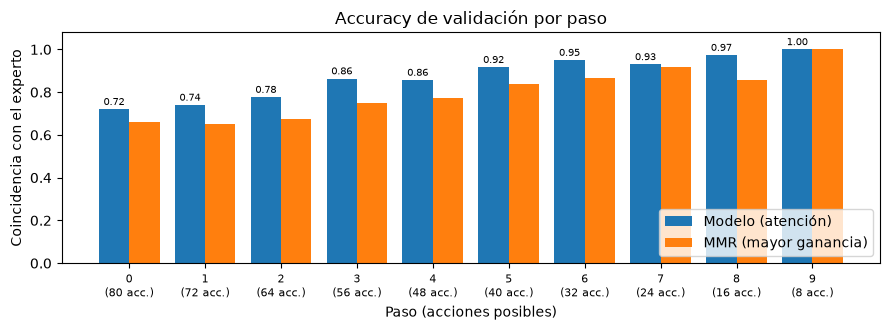

Accuracy global -> modelo: 0.873 | MMR: 0.799


In [24]:
model.eval()
with torch.no_grad():
    pred_val = torch.cat([model(X_val[s:s + 1024]).argmax(-1) for s in range(0, len(X_val), 1024)]).numpy()
acc_step = (pred_val == Y_val.numpy()).reshape(-1, N_WEAPONS).mean(0)
mmr_pick = np.argmax(np.where(X_val[:, :, COL_MASK].numpy() == 1, -1, X_val[:, :, 8].numpy()), 1)
acc_mmr_step = (mmr_pick == Y_val.numpy()).reshape(-1, N_WEAPONS).mean(0)

fig, ax = plt.subplots(figsize=(9, 3.4))
xs = np.arange(N_WEAPONS)
ax.bar(xs - 0.2, acc_step, 0.4, color="tab:blue", label="Modelo (atención)")
ax.bar(xs + 0.2, acc_mmr_step, 0.4, color="tab:orange", label="MMR (mayor ganancia)")
ax.set_xticks(xs); ax.set_xticklabels([f"{k}\n({(N_WEAPONS - k) * N_TARGETS} acc.)" for k in xs], fontsize=8)
ax.set_xlabel("Paso (acciones posibles)"); ax.set_ylabel("Coincidencia con el experto"); ax.set_ylim(0, 1.08)
for i, a in enumerate(acc_step): ax.text(i - 0.2, a + 0.02, f"{a:.2f}", ha="center", fontsize=7.5)
ax.legend(loc="lower right"); ax.set_title("Accuracy de validación por paso")
plt.tight_layout(); guardar(fig, "acc_por_paso"); plt.show()
print(f"Accuracy global -> modelo: {acc_step.mean():.3f} | MMR: {acc_mmr_step.mean():.3f}")

## 9. Evaluación post-entrenamiento

`ModelEvalActions` (definido arriba) calcula `state2vec`, obtiene las probabilidades del modelo y retorna `(acción, puntaje)` para cada acción legal de `env.gen_actions`. Lo integramos en el mismo `GreedyAgent` que implementa MMR: **solo cambia quién evalúa las acciones**.

### ¿Qué mira el puntero?
Para el estado de ejemplo de la sección 5, reordenamos la salida del modelo (80 probabilidades de pares) como una matriz armas × objetivos.

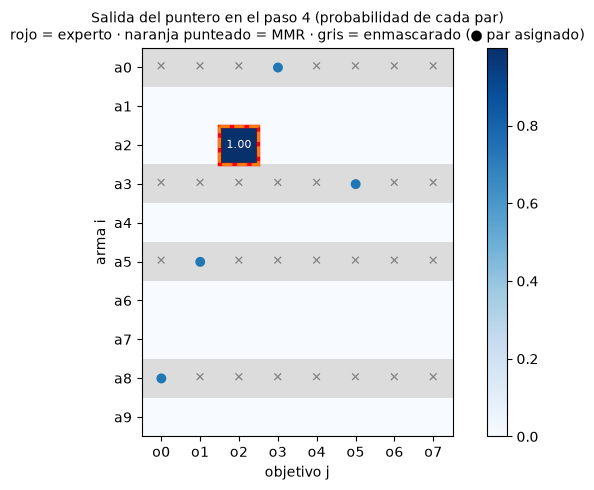

El modelo elige arma 2 -> obj 2 (p = 1.00) | experto: arma 2 -> obj 2 | MMR: arma 2 -> obj 2


In [25]:
with torch.no_grad():
    p_demo = model(torch.tensor(x_demo), return_probabilities=True)[0].numpy()
grid = p_demo[1:].reshape(N_WEAPONS, N_TARGETS)
masked = x_demo[1:, COL_MASK].reshape(N_WEAPONS, N_TARGETS) == 1
fig, ax = plt.subplots(figsize=(7.5, 5))
im = ax.imshow(np.ma.masked_where(masked, grid), cmap="Blues", vmin=0, vmax=grid.max())
ax.imshow(np.ma.masked_where(~masked, np.ones_like(grid)), cmap="Greys", vmin=0, vmax=3, alpha=0.6)
for i in range(N_WEAPONS):
    for j in range(N_TARGETS):
        if masked[i, j]:
            ax.text(j, i, "✕" if x_demo[1 + i * N_TARGETS + j, 5] == 0 else "●", ha="center", va="center",
                    color="gray" if x_demo[1 + i * N_TARGETS + j, 5] == 0 else "tab:blue", fontsize=9)
        elif grid[i, j] > 0.01:
            ax.text(j, i, f"{grid[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if grid[i, j] > grid.max() / 2 else "black")
ei, ej = chosen_demo[1]
ax.add_patch(plt.Rectangle((ej - 0.5, ei - 0.5), 1, 1, fill=False, ec="red", lw=2.5))
mmr_r = int(np.argmax(np.where(x_demo[:, COL_MASK] == 1, -1, x_demo[:, 8])))
mi, mj = (mmr_r - 1) // N_TARGETS, (mmr_r - 1) % N_TARGETS
ax.add_patch(plt.Rectangle((mj - 0.5, mi - 0.5), 1, 1, fill=False, ec="tab:orange", lw=2, ls="--"))
ax.set_xticks(range(N_TARGETS)); ax.set_xticklabels([f"o{j}" for j in range(N_TARGETS)])
ax.set_yticks(range(N_WEAPONS)); ax.set_yticklabels([f"a{i}" for i in range(N_WEAPONS)])
ax.set_xlabel("objetivo j"); ax.set_ylabel("arma i")
ax.set_title("Salida del puntero en el paso 4 (probabilidad de cada par)\n"
             "rojo = experto · naranja punteado = MMR · gris = enmascarado (● par asignado)", fontsize=10)
plt.colorbar(im, ax=ax, fraction=0.04); plt.tight_layout(); guardar(fig, "salida"); plt.show()
print(f"El modelo elige arma {int(np.argmax(p_demo) - 1) // N_TARGETS} -> obj {int(np.argmax(p_demo) - 1) % N_TARGETS} "
      f"(p = {p_demo.max():.2f}) | experto: arma {ei} -> obj {ej} | MMR: arma {mi} -> obj {mj}")

### Rollout en una instancia nueva

Modelo (atención): [0, 0, 4, 2, 6, 1, 3, 6, 5, 7] costo = 44.456
MMR:               [0, 0, 4, 7, 2, 1, 3, 6, 5, 4] costo = 47.233
Experto (ILS):     [0, 0, 4, 2, 7, 1, 3, 6, 5, 4] costo = 44.284


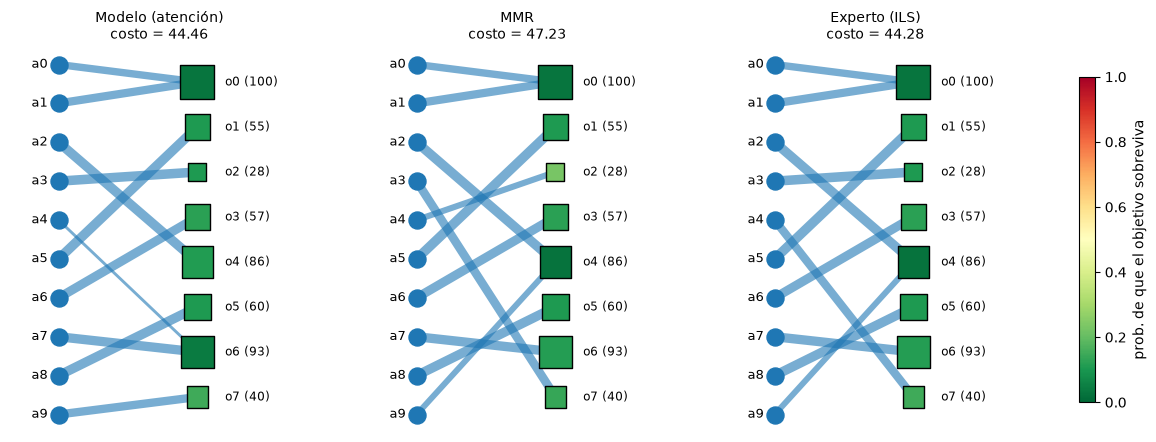

In [26]:
np.random.seed(45)
test_inst = WTAP_Instance.random()                        # misma instancia de ejemplo de la Tarea 4
sol_model, *_ = SingleAgentSolver(env, GreedyAgent(ModelEvalActions(model))).solve(WTAP_State(test_inst))
sol_mmr_t, *_ = mmr_agent.solve(WTAP_State(test_inst))
a_exp, c_exp = ils(test_inst, rng=np.random.default_rng(45))
print("Modelo (atención):", sol_model.assignment, f"costo = {sol_model.cost:.3f}")
print("MMR:              ", sol_mmr_t.assignment, f"costo = {sol_mmr_t.cost:.3f}")
print("Experto (ILS):    ", a_exp, f"costo = {c_exp:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, (name, a) in zip(axes, [("Modelo (atención)", sol_model.assignment), ("MMR", sol_mmr_t.assignment),
                                ("Experto (ILS)", a_exp)]):
    sc = plot_partial(test_inst, a, ax=ax, title=f"{name}\ncosto = {cost_of(test_inst, a):.2f}")
fig.colorbar(sc, ax=axes, fraction=0.015, label="prob. de que el objetivo sobreviva")
guardar(fig, "rollout_ejemplo"); plt.show()

### Evaluación en las 50 instancias de prueba
- **Instancias:** 50 instancias propias de 10 armas × 8 objetivos, nunca vistas en entrenamiento (semilla 2024). Son **las mismas de la Tarea 4**, así que la MLP de esa tarea (gap 4,42 %) sirve de referencia.
- **Métrica:** $\text{gap} = 100\,(\text{costo} / \text{costo del experto} - 1)$, con el experto ILS como referencia. En instancias 10×8 el ILS coincide con el óptimo exacto en todas las instancias verificadas (sección 3), así que este gap es, en la práctica, el gap respecto del óptimo.
- **Baselines:** MMR (heurística constructiva clásica) y un **constructivo aleatorio** (el mismo `GreedyAgent` con puntajes aleatorios: en cada paso elige un par válido al azar). Reportamos **media ± desviación estándar**.

In [27]:
GAP_MLP_T4 = 4.415       # gap promedio de la MLP de la Tarea 4 en estas mismas 50 instancias
test_insts = [inst for inst, _, _ in test_solved]

def make_random_eval(seed):
    # constructivo aleatorio: puntajes uniformes, así el GreedyAgent elige un par válido al azar
    rng = np.random.default_rng(seed)
    @handle_multiple_states
    def evalRandomActions(state, env):
        return [(action, rng.random()) for action in env.gen_actions(state, "constructive")]
    return evalRandomActions


results = {
    "Modelo (atención)": rollout_costs(ModelEvalActions(model), test_insts),
    "MMR (heurística clásica)": rollout_costs(evalConstructiveActions, test_insts),
    "Aleatorio": rollout_costs(make_random_eval(0), test_insts),
    "Experto (ILS)": test_expert,
}

def print_gaps(results, expert_costs, title):
    print(f"--- {title} ---")
    print(f"{'Método':<26} {'Costo (media ± desv.)':>22} {'Gap % (media ± desv.)':>22} {'Mediana':>8} {'% óptimo':>9}")
    for name, costs in results.items():
        g = gap(costs, expert_costs)
        print(f"{name:<26} {costs.mean():>12.2f} ± {costs.std():<7.2f} {g.mean():>12.2f} ± {g.std():<7.2f} "
              f"{np.median(g):>7.2f}% {100 * np.mean(g < 1e-6):>8.0f}%")
    print()

print_gaps(results, test_expert, "50 instancias de prueba, 10 armas × 8 objetivos")
print(f"Referencia: MLP de la Tarea 4 (orden fijo de armas) -> gap promedio {GAP_MLP_T4:.2f}%")
g_model, g_mmr = gap(results["Modelo (atención)"], test_expert), gap(results["MMR (heurística clásica)"], test_expert)
wins, ties = np.mean(g_model < g_mmr - 1e-9), np.mean(np.abs(g_model - g_mmr) <= 1e-9)
print(f"Modelo vs MMR: mejor en {100 * wins:.0f}% de las instancias, igual en {100 * ties:.0f}%, "
      f"peor en {100 * (1 - wins - ties):.0f}%")

--- 50 instancias de prueba, 10 armas × 8 objetivos ---
Método                      Costo (media ± desv.)  Gap % (media ± desv.)  Mediana  % óptimo
Modelo (atención)                 47.70 ± 8.85            2.97 ± 3.68       1.85%       30%
MMR (heurística clásica)          49.83 ± 8.90            7.68 ± 4.91       7.75%        6%
Aleatorio                        186.15 ± 55.39         309.72 ± 131.77   291.64%        0%
Experto (ILS)                     46.26 ± 7.98            0.00 ± 0.00       0.00%      100%

Referencia: MLP de la Tarea 4 (orden fijo de armas) -> gap promedio 4.42%
Modelo vs MMR: mejor en 72% de las instancias, igual en 20%, peor en 8%


**Tiempo de inferencia por instancia** (una instancia a la vez, misma máquina): el modelo hace W pasadas por la red; el experto ejecuta 100 iteraciones de búsqueda local.

In [28]:
def time_per_instance(fn, insts, reps=1):
    t0 = time.perf_counter()
    for _ in range(reps):
        for inst in insts:
            fn(inst)
    return 1000 * (time.perf_counter() - t0) / (reps * len(insts))

model_agent = SingleAgentSolver(env, GreedyAgent(ModelEvalActions(model)))
sub = test_insts[:20]
times_ms = {
    "Modelo (atención)": time_per_instance(lambda i: model_agent.solve(WTAP_State(i)), sub),
    "MMR (heurística clásica)": time_per_instance(lambda i: mmr(i), sub, reps=5),
    "Experto (ILS)": time_per_instance(lambda i: ils(i, rng=np.random.default_rng(0)), sub),
}
for n, t in times_ms.items():
    print(f"{n:<26} {t:8.2f} ms por instancia")

Modelo (atención)             18.06 ms por instancia
MMR (heurística clásica)       0.12 ms por instancia
Experto (ILS)                 20.06 ms por instancia


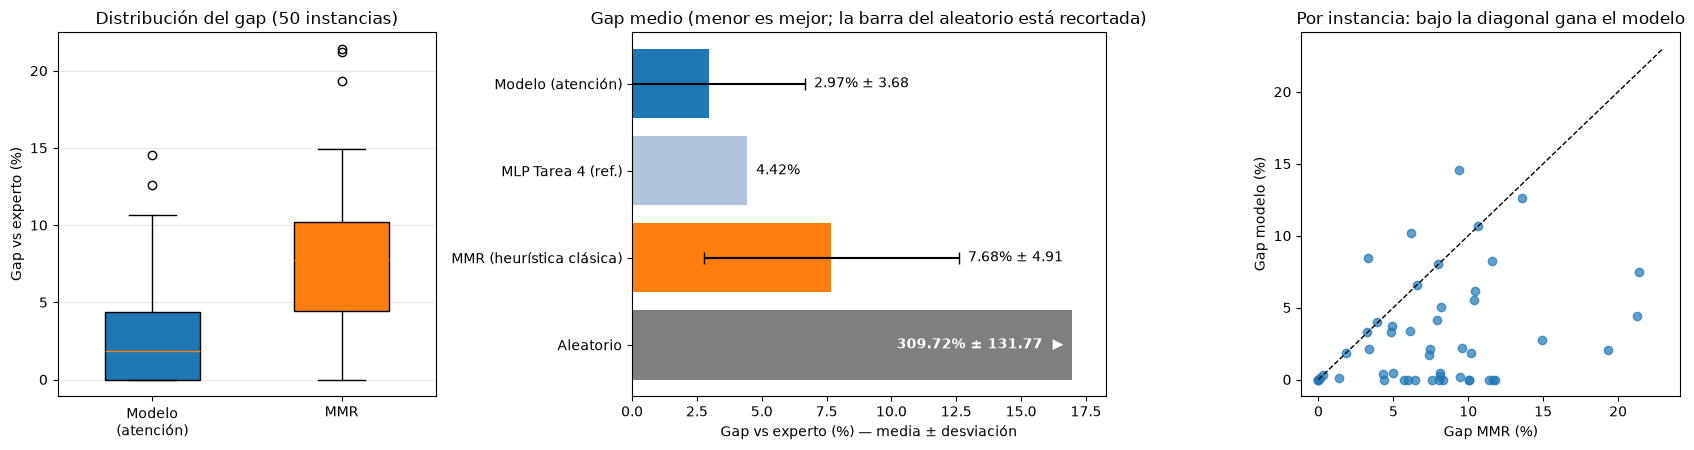

In [29]:
COLORES = {"Modelo (atención)": "tab:blue", "MMR (heurística clásica)": "tab:orange", "Aleatorio": "tab:gray",
           "Experto (ILS)": "tab:green", "MLP Tarea 4 (ref.)": "lightsteelblue"}
g_rand = gap(results["Aleatorio"], test_expert)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1, 1.25, 1]})
bp = axes[0].boxplot([g_model, g_mmr], tick_labels=["Modelo\n(atención)", "MMR"], patch_artist=True, widths=0.5)
for patch, n in zip(bp["boxes"], ["Modelo (atención)", "MMR (heurística clásica)"]): patch.set_facecolor(COLORES[n])
axes[0].set_ylabel("Gap vs experto (%)"); axes[0].set_title("Distribución del gap (50 instancias)")
axes[0].grid(axis="y", alpha=0.3)

bars = [("Modelo (atención)", g_model.mean(), g_model.std()), ("MLP Tarea 4 (ref.)", GAP_MLP_T4, None),
        ("MMR (heurística clásica)", g_mmr.mean(), g_mmr.std()), ("Aleatorio", g_rand.mean(), g_rand.std())]
xmax = max(m + (s or 0) for n, m, s in bars if n != "Aleatorio") * 1.45
for k, (n, m, s) in enumerate(bars[::-1]):
    shown = min(m, xmax * 0.93)
    axes[1].barh(k, shown, color=COLORES[n], xerr=None if (s is None or n == "Aleatorio") else s, capsize=4)
    label = f"{m:.2f}%" + ("" if s is None else f" ± {s:.2f}")
    if n == "Aleatorio":
        axes[1].text(shown * 0.98, k, f"{label}  ▶", va="center", ha="right", color="white", fontweight="bold")
    else:
        axes[1].text(m + (s or 0) + xmax * 0.02, k, label, va="center")
axes[1].set_yticks(range(len(bars))); axes[1].set_yticklabels([n for n, _, _ in bars[::-1]])
axes[1].set_xlim(0, xmax); axes[1].set_xlabel("Gap vs experto (%) — media ± desviación")
axes[1].set_title("Gap medio (menor es mejor; la barra del aleatorio está recortada)")

lim = max(g_model.max(), g_mmr.max()) * 1.05 + 0.5
axes[2].scatter(g_mmr, g_model, color="tab:blue", alpha=0.7)
axes[2].plot([0, lim], [0, lim], "k--", lw=1)
axes[2].set_xlabel("Gap MMR (%)"); axes[2].set_ylabel("Gap modelo (%)")
axes[2].set_title("Por instancia: bajo la diagonal gana el modelo")
plt.tight_layout(); guardar(fig, "comparacion"); plt.show()

## 10. Desempeño por tamaño de instancia

El modelo se entrenó **solo con instancias 10×8** (81 filas). Como ningún peso depende de W ni de T, lo evaluamos sin cambios en cinco tamaños: **5×4, 10×8, 15×10, 20×15 y 30×20** (de 21 a 601 filas), con 30 instancias nuevas por tamaño (en 10×8 usamos las 50 de prueba). En 5×4 calculamos además el **óptimo exacto por fuerza bruta** ($4^5$ asignaciones) para verificar que el ILS es óptimo también ahí. En los tamaños grandes el experto es la mejor solución conocida del ILS.

In [30]:
def exact_brute(inst):
    # óptimo exacto enumerando las T^W asignaciones (solo para instancias muy pequeñas)
    W, T = inst.probs.shape
    best_c, best_a = np.inf, None
    for a in itertools.product(range(T), repeat=W):
        c = cost_of(inst, a)
        if c < best_c:
            best_c, best_a = c, a
    return list(best_a), best_c


SIZES = [(5, 4), (10, 8), (15, 10), (20, 15), (30, 20)]
N_SIZE = 30
size_res, size_exact = {}, {}
for (W, T) in SIZES:
    t0 = time.time()
    label = f"{W}×{T}"
    if (W, T) == (N_WEAPONS, N_TARGETS):
        insts, exp_c = test_insts, test_expert
    else:
        solved = solve_instances(W, T, N_SIZE, seed=3000 + W)
        insts, exp_c = [i for i, _, _ in solved], np.array([c for _, _, c in solved])
    res = {"Modelo (atención)": rollout_costs(ModelEvalActions(model), insts),
           "MMR (heurística clásica)": rollout_costs(evalConstructiveActions, insts),
           "Aleatorio": rollout_costs(make_random_eval(W), insts),
           "Experto (ILS)": exp_c}
    if (W, T) == (5, 4):
        opt = np.array([exact_brute(i)[1] for i in insts])
        size_exact[label] = int(np.sum(np.abs(opt - exp_c) < 1e-7))
        print(f"Óptimo exacto (fuerza bruta) en {label}: el ILS lo alcanza en {size_exact[label]}/{len(insts)} instancias")
    size_res[label] = {n: gap(c, exp_c) for n, c in res.items()}
    print_gaps(res, exp_c, f"{len(insts)} instancias de {W} armas × {T} objetivos ({1 + W * T} filas) — {time.time() - t0:.0f} s")

Óptimo exacto (fuerza bruta) en 5×4: el ILS lo alcanza en 30/30 instancias
--- 30 instancias de 5 armas × 4 objetivos (21 filas) — 1 s ---
Método                      Costo (media ± desv.)  Gap % (media ± desv.)  Mediana  % óptimo
Modelo (atención)                 27.90 ± 8.92            1.67 ± 4.21       0.00%       77%
MMR (heurística clásica)          29.16 ± 9.19            6.46 ± 7.87       3.29%       40%
Aleatorio                         95.80 ± 31.32         258.79 ± 102.08   255.61%        0%
Experto (ILS)                     27.41 ± 8.67            0.00 ± 0.00       0.00%      100%



--- 50 instancias de 10 armas × 8 objetivos (81 filas) — 0 s ---
Método                      Costo (media ± desv.)  Gap % (media ± desv.)  Mediana  % óptimo
Modelo (atención)                 47.70 ± 8.85            2.97 ± 3.68       1.85%       30%
MMR (heurística clásica)          49.83 ± 8.90            7.68 ± 4.91       7.75%        6%
Aleatorio                        191.45 ± 50.99         316.20 ± 100.12   304.27%        0%
Experto (ILS)                     46.26 ± 7.98            0.00 ± 0.00       0.00%      100%



--- 30 instancias de 15 armas × 10 objetivos (151 filas) — 1 s ---
Método                      Costo (media ± desv.)  Gap % (media ± desv.)  Mediana  % óptimo
Modelo (atención)                 36.67 ± 5.38            5.28 ± 3.87       4.32%        7%
MMR (heurística clásica)          37.59 ± 5.83            7.82 ± 4.92       7.10%        3%
Aleatorio                        192.14 ± 56.48         454.33 ± 159.71   446.99%        0%
Experto (ILS)                     34.94 ± 5.68            0.00 ± 0.00       0.00%      100%



--- 30 instancias de 20 armas × 15 objetivos (301 filas) — 2 s ---
Método                      Costo (media ± desv.)  Gap % (media ± desv.)  Mediana  % óptimo
Modelo (atención)                 69.39 ± 8.08            3.99 ± 3.05       3.36%        0%
MMR (heurística clásica)          70.59 ± 8.65            5.71 ± 3.11       5.96%        0%
Aleatorio                        314.45 ± 63.65         373.09 ± 89.88    376.24%        0%
Experto (ILS)                     66.78 ± 7.96            0.00 ± 0.00       0.00%      100%



--- 30 instancias de 30 armas × 20 objetivos (601 filas) — 6 s ---
Método                      Costo (media ± desv.)  Gap % (media ± desv.)  Mediana  % óptimo
Modelo (atención)                 64.53 ± 6.69            5.30 ± 2.89       5.72%        0%
MMR (heurística clásica)          64.88 ± 6.65            5.89 ± 2.99       6.12%        0%
Aleatorio                        419.45 ± 61.85         587.75 ± 103.96   569.48%        0%
Experto (ILS)                     61.28 ± 6.10            0.00 ± 0.00       0.00%      100%



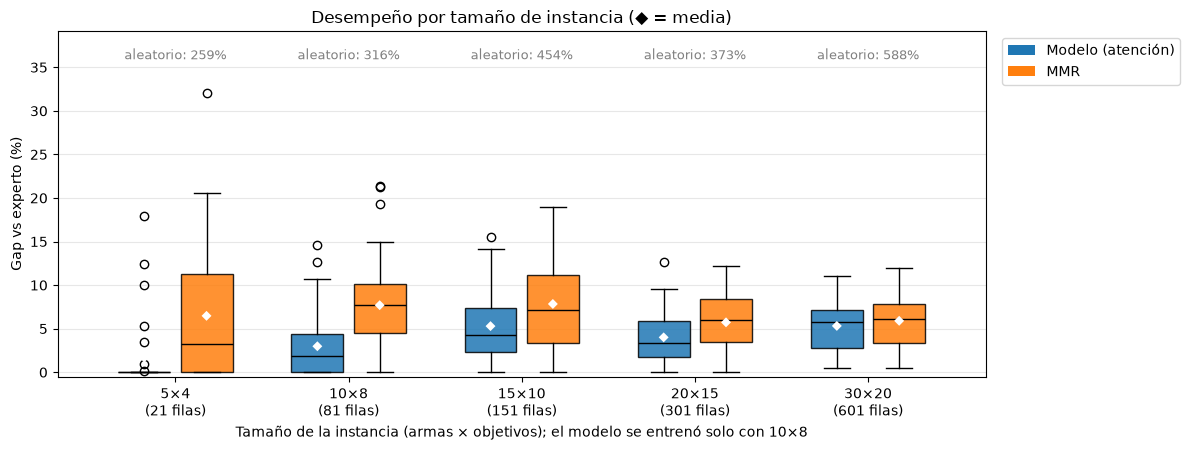

Tamaño              Modelo (atención)     MMR (heurística clásica)                    Aleatorio
5×4                   1.67 ± 4.21                  6.46 ± 7.87                258.79 ± 102.08  
10×8                  2.97 ± 3.68                  7.68 ± 4.91                316.20 ± 100.12  
15×10                 5.28 ± 3.87                  7.82 ± 4.92                454.33 ± 159.71  
20×15                 3.99 ± 3.05                  5.71 ± 3.11                373.09 ± 89.88   
30×20                 5.30 ± 2.89                  5.89 ± 2.99                587.75 ± 103.96  


In [31]:
labels = list(size_res)
fig, ax = plt.subplots(figsize=(12, 4.6))
pos = np.arange(len(labels))
for off, n, col in [(-0.18, "Modelo (atención)", "tab:blue"), (0.18, "MMR (heurística clásica)", "tab:orange")]:
    bp = ax.boxplot([size_res[l][n] for l in labels], positions=pos + off, widths=0.3, patch_artist=True,
                    showfliers=True, medianprops=dict(color="black"))
    for patch in bp["boxes"]:
        patch.set_facecolor(col); patch.set_alpha(0.85)
    for k, l in enumerate(labels):
        ax.text(k + off, size_res[l][n].mean(), "◆", ha="center", va="center", color="white", fontsize=9)
top = max(max(size_res[l]["Modelo (atención)"].max(), size_res[l]["MMR (heurística clásica)"].max()) for l in labels)
for k, l in enumerate(labels):
    ax.text(k, top * 1.12, f"aleatorio: {size_res[l]['Aleatorio'].mean():.0f}%", ha="center", fontsize=9, color="gray")
ax.set_xticks(pos); ax.set_xticklabels([f"{l}\n({1 + int(l.split('×')[0]) * int(l.split('×')[1])} filas)" for l in labels])
ax.set_ylim(-0.5, top * 1.22)
ax.set_xlabel("Tamaño de la instancia (armas × objetivos); el modelo se entrenó solo con 10×8")
ax.set_ylabel("Gap vs experto (%)")
ax.legend([plt.Rectangle((0, 0), 1, 1, fc="tab:blue"), plt.Rectangle((0, 0), 1, 1, fc="tab:orange")],
          ["Modelo (atención)", "MMR"], loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("Desempeño por tamaño de instancia (◆ = media)")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); guardar(fig, "tamanos"); plt.show()

print(f"{'Tamaño':<8} " + " ".join(f"{n:>28}" for n in ["Modelo (atención)", "MMR (heurística clásica)", "Aleatorio"]))
for l in labels:
    print(f"{l:<8} " + " ".join(f"{size_res[l][n].mean():>17.2f} ± {size_res[l][n].std():<8.2f}"
                                for n in ["Modelo (atención)", "MMR (heurística clásica)", "Aleatorio"]))

## 11. Discusión y conclusiones

### ¿Qué funcionó bien?
- **Representación por pares con features tomadas de las heurísticas.** El modelo coincide con el experto en **87,3 %** de las decisiones de validación, frente a 79,9 % de la regla "mayor ganancia" de MMR.
- **Calidad de las soluciones.** En las 50 instancias de prueba el gap es **2,97 ± 3,68 %** (mediana 1,85 %), contra 7,68 ± 4,91 % de MMR, 4,42 % de la MLP de la Tarea 4 y 310 % del constructivo aleatorio. Encuentra la solución óptima en 30 % de las instancias y supera a MMR en 72 % (empata en 20 %).
- **Entrenamiento estable y sin sobreajuste.** En la mejor época (la 48) la pérdida de entrenamiento y la de validación son prácticamente iguales (0,313 vs 0,313); al final la diferencia apenas llega a 0,027, y el early stopping restaura la mejor época.
- **Generalización de tamaño.** El mismo modelo, entrenado solo con 10×8, supera a MMR en los 5 tamaños evaluados (de 21 a 601 filas).

### ¿Qué no resultó como se esperaba?
- **El Dropout no ayudó** (barrido de la Tarea 5): con 60 000 ejemplos y pesos compartidos entre filas, el modelo no llega a sobreajustar.
- **Las primeras decisiones siguen siendo las más difíciles:** accuracy 72 % en el paso 0 (80 acciones posibles) frente a 100 % en el último.
- **La ventaja sobre MMR se reduce al crecer la instancia:** el gap pasa de 2,97 % en 10×8 a 5,30 % en 30×20, y la diferencia con MMR baja de 4,8 a 0,6 puntos. Curiosamente, en 5×4 el modelo es aún mejor que en el tamaño de entrenamiento (1,67 %).
- **Costo de inferencia:** 18,1 ms por instancia 10×8, del mismo orden que el propio ILS (20,1 ms), porque el encoder se recalcula en cada uno de los W pasos y la atención es cuadrática en el número de filas.

### ¿Qué mejoraríamos?
- **Decoder con glimpse y atención multi-cabeza** (arquitectura de Kool et al. vista en clases), y recorte de logits con tanh.
- **Entrenar con tamaños mixtos** (por ejemplo, de 5×4 a 20×15) para mejorar la generalización a instancias grandes.
- **DAgger o aprendizaje por refuerzo** para corregir el *distribution shift* tras un error temprano.
- **Codificar armas y objetivos por separado** ($W + T$ elementos) con un puntero bilineal sobre pares, para reducir el costo cuadrático y poder codificar una sola vez por instancia.

In [32]:
summary = {
    "n_train_instances": len(train_solved), "n_train_samples": int(len(Y_train)),
    "n_val_samples": int(len(Y_val)), "n_test_instances": len(test_solved), "n_test_samples": int(len(Y_test)),
    "vec_len": VEC_LEN, "features": FEATURES, "n_rows": int(X_train.shape[1]),
    "final_model": best_name, "final_config": best["config"], "final_params": int(best["params"]),
    "val_acc_final": float(best["val_acc"]), "best_epoch_final": int(history["best_epoch"]),
    "epochs_final": len(history["val_loss"]),
    "experiments": {n: {"val_acc": float(e["val_acc"]), "val_loss": float(e["val_loss"]), "gap_val": float(e["gap"]),
                        "params": int(e["params"]), "config": e["config"]} for n, e in experiments.items()},
    "gap_mmr_val": float(gap_mmr_val),
    "acc_step": [float(a) for a in acc_step], "acc_mmr_step": [float(a) for a in acc_mmr_step],
    "test": {n: {"mean_cost": float(c.mean()), "std_cost": float(c.std()),
                 "mean_gap": float(gap(c, test_expert).mean()), "std_gap": float(gap(c, test_expert).std()),
                 "median_gap": float(np.median(gap(c, test_expert))),
                 "pct_optimal": float(100 * np.mean(gap(c, test_expert) < 1e-6))} for n, c in results.items()},
    "gap_mlp_t4": GAP_MLP_T4,
    "model_vs_mmr": {"wins": float(wins), "ties": float(ties)},
    "times_ms": {n: float(t) for n, t in times_ms.items()},
    "sizes": {l: {n: {"mean": float(g.mean()), "std": float(g.std()), "median": float(np.median(g)), "n": int(len(g))}
                  for n, g in d.items()} for l, d in size_res.items()},
    "exact_check_5x4": size_exact,
    "hparams": HPARAMS, "convergence": {k: float(v) for k, v in conv.items()},
    "dropout_sweep_t5": {str(k): v for k, v in DROPOUT_SWEEP_T5.items()},
    "gap_val_final": float(best["gap"]),
    "demo": {"step": K_DEMO, "assignment": [int(v) for v in st_demo.assignment], "chosen": list(chosen_demo[1]),
             "row": int(row_demo), "mmr": [int(mi), int(mj)],
             "model": [int(np.argmax(p_demo) - 1) // N_TARGETS, int(np.argmax(p_demo) - 1) % N_TARGETS],
             "p_model": float(p_demo.max()), "n_actions": len(actions_demo),
             "expert_solution": sol_ils, "expert_cost": float(cost_ils),
             "ej_step": K_EJ, "ej_chosen": list(chosen_ej[1]), "ej_n_actions": len(actions_ej),
             "steps": [{"k": k, "free": len(st.free_weapons), "n_actions": len(acts), "chosen": list(ch[1]),
                        "mmr": list(max(evalConstructiveActions(st, env), key=lambda e: e[1])[0][1])}
                       for k, (st, acts, ch) in enumerate(demo_steps)]},
}
with open("figuras_proyecto/resultados.json", "w") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False, default=int)
print(json.dumps(summary["test"], indent=2, ensure_ascii=False))

{
  "Modelo (atención)": {
    "mean_cost": 47.6968017214299,
    "std_cost": 8.853457487722414,
    "mean_gap": 2.9677121395262445,
    "std_gap": 3.6828109110498572,
    "median_gap": 1.8500830598814577,
    "pct_optimal": 30.0
  },
  "MMR (heurística clásica)": {
    "mean_cost": 49.83016348193226,
    "std_cost": 8.90448251504616,
    "mean_gap": 7.682223203939117,
    "std_gap": 4.907487710076813,
    "median_gap": 7.753805286468007,
    "pct_optimal": 6.0
  },
  "Aleatorio": {
    "mean_cost": 186.1545843256204,
    "std_cost": 55.38606110015561,
    "mean_gap": 309.72082144224487,
    "std_gap": 131.7661223573169,
    "median_gap": 291.6438956091192,
    "pct_optimal": 0.0
  },
  "Experto (ILS)": {
    "mean_cost": 46.26281573773545,
    "std_cost": 7.975278195834008,
    "mean_gap": 0.0,
    "std_gap": 0.0,
    "median_gap": 0.0,
    "pct_optimal": 100.0
  }
}
